In [1]:
from pathlib import Path
from collections import Counter
import json
import random
import pandas as pd

# Reproducibility
SEED = 42
random.seed(SEED)

# Project paths
PROJECT_ROOT = Path.cwd().parent

LABEL_ROOT = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "bdd100k_labels_extracted"
    / "100k"
)

TRAIN_LABELS = LABEL_ROOT / "train"
VAL_LABELS = LABEL_ROOT / "val"

OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "nightsight_10k"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Target dataset allocation
TARGET_COUNTS = {
    "baseline_train": 4000,
    "adaptation_train": 3000,
    "validation": 1500,
    "final_evaluation": 1500
}

TARGET_CLASSES = ["car", "person", "bus"]

print("Project:", PROJECT_ROOT)
print("Output:", OUTPUT_DIR)

print("\nDataset allocation:")
display(pd.DataFrame(
    TARGET_COUNTS.items(),
    columns=["Subset", "Images"]
))

print("\nTotal images:", sum(TARGET_COUNTS.values()))

assert TRAIN_LABELS.exists()
assert VAL_LABELS.exists()
assert sum(TARGET_COUNTS.values()) == 10000

print("\nConfiguration verified.")

Project: c:\CH\NightSight
Output: c:\CH\NightSight\data\processed\nightsight_10k

Dataset allocation:


,Subset,Images
0,baseline_train,4000
1,adaptation_train,3000
2,validation,1500
3,final_evaluation,1500



Total images: 10000

Configuration verified.


In [2]:
import json
from tqdm.auto import tqdm

def build_metadata_index(label_dir, split_name):

    records = []

    json_files = sorted(label_dir.glob("*.json"))

    for json_path in tqdm(json_files, desc=f"Indexing {split_name}"):

        with open(json_path, "r", encoding="utf-8") as f:
            data = json.load(f)

        attributes = data.get("attributes", {})
        timeofday = attributes.get("timeofday", "undefined")

        counts = Counter()
        invalid_box_count = 0

        for frame in data.get("frames", []):
            for obj in frame.get("objects", []):

                category = obj.get("category")

                if category not in TARGET_CLASSES:
                    continue

                counts[category] += 1

                box = obj.get("box2d")

                if not box:
                    invalid_box_count += 1
                    continue

                x1 = box.get("x1")
                y1 = box.get("y1")
                x2 = box.get("x2")
                y2 = box.get("y2")

                if None in (x1, y1, x2, y2):
                    invalid_box_count += 1
                elif x2 <= x1 or y2 <= y1:
                    invalid_box_count += 1

        records.append({
            "image_id": json_path.stem,
            "split": split_name,
            "timeofday": timeofday,
            "annotation_path": str(json_path.resolve()),
            "car_count": counts["car"],
            "person_count": counts["person"],
            "bus_count": counts["bus"],
            "total_target_objects": sum(counts.values()),
            "invalid_box_count": invalid_box_count
        })

    return pd.DataFrame(records)


train_metadata = build_metadata_index(TRAIN_LABELS, "train")
val_metadata = build_metadata_index(VAL_LABELS, "val")

metadata = pd.concat(
    [train_metadata, val_metadata],
    ignore_index=True
)

metadata.to_csv(
    OUTPUT_DIR / "metadata_index.csv",
    index=False
)

print("\nMetadata indexing completed.")
print("Total records:", len(metadata))
print("Train records:", len(train_metadata))
print("Validation records:", len(val_metadata))
print("Unique image IDs:", metadata["image_id"].nunique())

display(metadata.head())

c:\CH\NightSight\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Indexing val: 100%|██████████| 10000/10000 [03:21<00:00, 49.54it/s]



Metadata indexing completed.
Total records: 80000
Train records: 70000
Validation records: 10000
Unique image IDs: 80000


,image_id,split,timeofday,annotation_path,car_count,person_count,bus_count,total_target_objects,invalid_box_count
0,0000f77c-6257be58,train,daytime,C:\CH\NightSight\data\raw\bdd100k_labels_extra...,2,0,0,2,0
1,0000f77c-62c2a288,train,dawn/dusk,C:\CH\NightSight\data\raw\bdd100k_labels_extra...,0,3,0,3,0
2,0000f77c-cb820c98,train,dawn/dusk,C:\CH\NightSight\data\raw\bdd100k_labels_extra...,7,0,0,7,0
3,0001542f-5ce3cf52,train,night,C:\CH\NightSight\data\raw\bdd100k_labels_extra...,9,0,1,10,0
4,0001542f-7c670be8,train,night,C:\CH\NightSight\data\raw\bdd100k_labels_extra...,3,1,0,4,0


In [3]:
# Basic metadata quality checks

print("DATASET QUALITY AUDIT")
print("=" * 50)

print("\nMissing values:")
display(metadata.isnull().sum().to_frame("Missing values"))

print("\nDuplicate image IDs:")
print(metadata["image_id"].duplicated().sum())

print("\nSplit distribution:")
display(metadata["split"].value_counts().to_frame("Images"))

print("\nTime-of-day distribution:")
display(
    pd.crosstab(
        metadata["split"],
        metadata["timeofday"]
    )
)

print("\nTarget object instances by split:")
display(
    metadata.groupby("split")[
        ["car_count", "person_count", "bus_count"]
    ].sum()
)

print("\nImages containing each class:")
display(
    pd.DataFrame({
        "Train": [
            (train_metadata[c] > 0).sum()
            for c in ["car_count", "person_count", "bus_count"]
        ],
        "Validation": [
            (val_metadata[c] > 0).sum()
            for c in ["car_count", "person_count", "bus_count"]
        ]
    }, index=["Car", "Person", "Bus"])
)

print("\nInvalid bounding-box records:")
print(metadata["invalid_box_count"].sum())

DATASET QUALITY AUDIT

Missing values:


,Missing values
image_id,0
split,0
timeofday,0
annotation_path,0
car_count,0
person_count,0
bus_count,0
total_target_objects,0
invalid_box_count,0



Duplicate image IDs:
0

Split distribution:


,Images
split,
train,70000
val,10000



Time-of-day distribution:


timeofday,dawn/dusk,daytime,night,undefined
split,,,,
train,5033,36800,28028,139
val,778,5258,3929,35



Target object instances by split:


,car_count,person_count,bus_count
split,,,
train,714121,91435,11688
val,102540,13265,1597



Images containing each class:


,Train,Validation
Car,69201,9879
Person,22104,3220
Bus,9003,1242



Invalid bounding-box records:
275


In [4]:
# Inspect invalid bounding-box annotations

invalid_records = metadata[
    metadata["invalid_box_count"] > 0
].copy()

print("Images containing invalid annotations:",
      len(invalid_records))

print("\nInvalid annotations by split:")
display(
    invalid_records.groupby("split")["invalid_box_count"]
    .agg(["count", "sum"])
)

print("\nInvalid annotations by time of day:")
display(
    invalid_records.groupby("timeofday")["invalid_box_count"]
    .agg(["count", "sum"])
)

print("\nImages with the highest invalid annotation counts:")
display(
    invalid_records.sort_values(
        "invalid_box_count",
        ascending=False
    ).head(15)[
        ["image_id", "split", "timeofday", "invalid_box_count"]
    ]
)

Images containing invalid annotations: 269

Invalid annotations by split:


,count,sum
split,,
train,233,238
val,36,37



Invalid annotations by time of day:


,count,sum
timeofday,,
dawn/dusk,25,26
daytime,141,146
night,103,103



Images with the highest invalid annotation counts:


,image_id,split,timeofday,invalid_box_count
8528,162995f1-0e43ba5e,train,daytime,2
29519,4b94bae4-48184270,train,dawn/dusk,2
45040,72f22fa5-8af4615c,train,daytime,2
48032,7a63357e-3b260064,train,daytime,2
77841,c55ab634-b93da9ef,val,daytime,2
5612,0e78c3ba-f603fddd,train,daytime,2
2023,0570f82d-5376271e,train,daytime,1
2648,07075bd4-07406294,train,daytime,1
4537,0bd143f9-c7d0cfdd,train,night,1
4590,0bf1c902-ee543be5,train,daytime,1


In [5]:
# Prepare candidate pools

# Exclude images with no valid target objects.
valid_metadata = metadata[
    (metadata["total_target_objects"] > 0) &
    (metadata["invalid_box_count"] == 0)
].copy()

# Separate the original splits and time-of-day groups.
day_candidates = valid_metadata[
    (valid_metadata["split"] == "train") &
    (valid_metadata["timeofday"] == "daytime")
].copy()

night_train_candidates = valid_metadata[
    (valid_metadata["split"] == "train") &
    (valid_metadata["timeofday"] == "night")
].copy()

night_val_candidates = valid_metadata[
    (valid_metadata["split"] == "val") &
    (valid_metadata["timeofday"] == "night")
].copy()

print("Candidate pool sizes:")
print("Daytime training:", len(day_candidates))
print("Nighttime training:", len(night_train_candidates))
print("Nighttime validation:", len(night_val_candidates))

print("\nNighttime adaptation class combinations:")

night_train_candidates = night_train_candidates.copy()

night_train_candidates["class_combination"] = night_train_candidates.apply(
    lambda row: " + ".join(
        cls for cls, col in [
            ("car", "car_count"),
            ("person", "person_count"),
            ("bus", "bus_count")
        ]
        if row[col] > 0
    ),
    axis=1
)

display(
    night_train_candidates["class_combination"]
    .value_counts()
    .to_frame("Available images")
)

Candidate pool sizes:
Daytime training: 36518
Nighttime training: 27605
Nighttime validation: 3859

Nighttime adaptation class combinations:


,Available images
class_combination,
car,20780
car + person,4917
car + bus,1255
car + person + bus,592
person,48
person + bus,7
bus,6


In [6]:
# Inspect daytime class combinations

day_candidates = day_candidates.copy()

day_candidates["class_combination"] = day_candidates.apply(
    lambda row: " + ".join(
        cls for cls, col in [
            ("car", "car_count"),
            ("person", "person_count"),
            ("bus", "bus_count")
        ]
        if row[col] > 0
    ),
    axis=1
)

print("Daytime training class combinations:")
display(
    day_candidates["class_combination"]
    .value_counts()
    .to_frame("Available images")
)

print("\nTotal object instances in daytime candidates:")
display(
    day_candidates[
        ["car_count", "person_count", "bus_count"]
    ].sum().to_frame("Object instances")
)

Daytime training class combinations:


,Available images
class_combination,
car,18644
car + person,11424
car + person + bus,3201
car + bus,3067
person,127
person + bus,29
bus,26



Total object instances in daytime candidates:


,Object instances
car_count,400186
person_count,65861
bus_count,8395


In [ ]:
# Verify proposed sampling quotas

day_quotas = {
    "car + person + bus": 800,
    "car + person": 1400,
    "car + bus": 500,
    "car": 1200,
    "person": 100
}

night_quotas = {
    "car + bus": 1200,
    "car + person": 900,
    "car": 900
}

def check_quotas(candidate_df, quotas, name):
    counts = candidate_df["class_combination"].value_counts()

    rows = []
    for category, required in quotas.items():
        available = int(counts.get(category, 0))
        rows.append({
            "category": category,
            "required": required,
            "available": available,
            "sufficient": available >= required
        })

    result = pd.DataFrame(rows)
    print(f"\n{name} quota feasibility:")
    display(result)

    if not result["sufficient"].all():
        raise ValueError(f"{name}: Insufficient candidates for one or more quotas.")

    print("Total requested:", sum(quotas.values()))

check_quotas(day_candidates, day_quotas, "Daytime baseline")
check_quotas(night_train_candidates, night_quotas, "Nighttime adaptation")


Daytime baseline quota feasibility:


,category,required,available,sufficient
0,car + person + bus,800,3201,True
1,car + person,1400,11424,True
2,car + bus,500,3067,True
3,car,1200,18644,True
4,person,100,127,True


Total requested: 4000

Nighttime adaptation quota feasibility:


,category,required,available,sufficient
0,car + bus,1200,1255,True
1,car + person,900,4917,True
2,car,900,20780,True


Total requested: 3000


In [8]:
# Inspect nighttime validation class combinations

night_val_candidates = night_val_candidates.copy()

night_val_candidates["class_combination"] = night_val_candidates.apply(
    lambda row: " + ".join(
        cls for cls, col in [
            ("car", "car_count"),
            ("person", "person_count"),
            ("bus", "bus_count")
        ]
        if row[col] > 0
    ),
    axis=1
)

print("Nighttime validation class combinations:")
display(
    night_val_candidates["class_combination"]
    .value_counts()
    .to_frame("Available images")
)

print("\nTotal object instances:")
display(
    night_val_candidates[
        ["car_count", "person_count", "bus_count"]
    ].sum().to_frame("Object instances")
)

Nighttime validation class combinations:


,Available images
class_combination,
car,2848
car + person,745
car + bus,176
car + person + bus,81
person,5
bus,3
person + bus,1



Total object instances:


,Object instances
car_count,35783
person_count,2832
bus_count,300


In [19]:
# Revised validation and final evaluation quotas

val_quotas = {
    "car": 1110,
    "car + person": 290,
    "car + bus": 65,
    "car + person + bus": 30,
    "person": 2,
    "bus": 1,
    "person + bus": 1
}

final_quotas = {
    "car": 1110,
    "car + person": 290,
    "car + bus": 65,
    "car + person + bus": 30,
    "person": 2,
    "bus": 2,
    "person + bus": 0
}

counts = night_val_candidates["class_combination"].value_counts()

rows = []

for category in val_quotas:
    required = val_quotas[category] + final_quotas[category]
    available = int(counts.get(category, 0))

    rows.append({
        "category": category,
        "validation": val_quotas[category],
        "final_evaluation": final_quotas[category],
        "required_total": required,
        "available": available,
        "sufficient": available >= required
    })

quota_check = pd.DataFrame(rows)

display(quota_check)

assert quota_check["sufficient"].all()
assert sum(val_quotas.values()) == 1499
assert sum(final_quotas.values()) == 1499
assert sum(val_quotas.values()) + sum(final_quotas.values()) == 2998

print("Validation quota:", sum(val_quotas.values()))
print("Final evaluation quota:", sum(final_quotas.values()))
print("Total:", sum(val_quotas.values()) + sum(final_quotas.values()))
print("All quota checks passed.")

,category,validation,final_evaluation,required_total,available,sufficient
0,car,1110,1110,2220,2848,True
1,car + person,290,290,580,745,True
2,car + bus,65,65,130,176,True
3,car + person + bus,30,30,60,81,True
4,person,2,2,4,5,True
5,bus,1,2,3,3,True
6,person + bus,1,0,1,1,True


Validation quota: 1499
Final evaluation quota: 1499
Total: 2998
All quota checks passed.


In [20]:
# Add one car-only image to each evaluation subset

val_quotas["car"] += 1
final_quotas["car"] += 1

assert sum(val_quotas.values()) == 1500
assert sum(final_quotas.values()) == 1500

print("Validation:", sum(val_quotas.values()))
print("Final evaluation:", sum(final_quotas.values()))
print("Combined:", sum(val_quotas.values()) + sum(final_quotas.values()))
print("Remaining car-only candidates:",
      2848 - val_quotas["car"] - final_quotas["car"])

print("Updated quotas verified.")

Validation: 1500
Final evaluation: 1500
Combined: 3000
Remaining car-only candidates: 626
Updated quotas verified.


In [23]:

# Reproducible sampling with cross-subset uniqueness

import random

SEED = 42
rng = random.Random(SEED)


def sample_category(df, quotas, subset_name):
    selected = []

    for category, required in quotas.items():
        candidates = df[
            df["class_combination"] == category
        ]

        if len(candidates) < required:
            raise ValueError(
                f"{subset_name}: insufficient candidates for {category}"
            )

        sampled_indices = rng.sample(
            list(candidates.index),
            required
        )

        selected.append(
            df.loc[sampled_indices].assign(subset=subset_name)
        )

    return pd.concat(selected, ignore_index=True)


# 1. Baseline training
baseline_selected = sample_category(
    day_candidates,
    day_quotas,
    "baseline_train"
)


# 2. Adaptation training
adaptation_selected = sample_category(
    night_train_candidates,
    night_quotas,
    "adaptation_train"
)


# 3. Combine validation and evaluation quotas
combined_val_quotas = {
    category: val_quotas[category] + final_quotas[category]
    for category in val_quotas
}


# 4. Sample the combined pool only once
combined_val_selected = sample_category(
    night_val_candidates,
    combined_val_quotas,
    "temporary"
)


# 5. Divide the selected pool without replacement
validation_parts = []
evaluation_parts = []

for category in combined_val_quotas:

    category_df = combined_val_selected[
        combined_val_selected["class_combination"] == category
    ].copy()

    category_indices = list(category_df.index)
    rng.shuffle(category_indices)

    val_count = val_quotas[category]

    validation_parts.append(
        category_df.loc[category_indices[:val_count]]
        .assign(subset="validation")
    )

    evaluation_parts.append(
        category_df.loc[category_indices[val_count:]]
        .assign(subset="final_evaluation")
    )


validation_selected = pd.concat(
    validation_parts, ignore_index=True
)

evaluation_selected = pd.concat(
    evaluation_parts, ignore_index=True
)


# 6. Combine all four subsets
manifest = pd.concat(
    [
        baseline_selected,
        adaptation_selected,
        validation_selected,
        evaluation_selected
    ],
    ignore_index=True
)


# 7. Verify the result
print("Subset counts:")
display(manifest["subset"].value_counts().to_frame("images"))

print("\nTotal images:", len(manifest))
print("Unique image IDs:", manifest["image_id"].nunique())
print("Duplicate image IDs:", manifest["image_id"].duplicated().sum())


# 8. Strict assertions
assert len(manifest) == 10000
assert manifest["image_id"].nunique() == 10000
assert manifest["image_id"].duplicated().sum() == 0

print("\nSampling completed successfully.")


Subset counts:


,images
subset,
baseline_train,4000
adaptation_train,3000
validation,1500
final_evaluation,1500



Total images: 10000
Unique image IDs: 10000
Duplicate image IDs: 0

Sampling completed successfully.


In [24]:
# Comprehensive manifest validation

print("Source split distribution:")
display(
    pd.crosstab(manifest["subset"], manifest["split"])
)

print("\nTime-of-day distribution:")
display(
    pd.crosstab(manifest["subset"], manifest["timeofday"])
)

print("\nClass-combination distribution:")
display(
    pd.crosstab(
        manifest["subset"],
        manifest["class_combination"]
    )
)

# Verify source split and time-of-day requirements
assert (manifest.loc[
    manifest["subset"] == "baseline_train", "split"
] == "train").all()

assert (manifest.loc[
    manifest["subset"] == "baseline_train", "timeofday"
] == "daytime").all()

assert (manifest.loc[
    manifest["subset"] == "adaptation_train", "split"
] == "train").all()

assert (manifest.loc[
    manifest["subset"] == "adaptation_train", "timeofday"
] == "night").all()

assert (manifest.loc[
    manifest["subset"].isin(["validation", "final_evaluation"]),
    "split"
] == "val").all()

assert (manifest.loc[
    manifest["subset"].isin(["validation", "final_evaluation"]),
    "timeofday"
] == "night").all()

# Verify no overlap between subsets
assert manifest.groupby("image_id")["subset"].nunique().max() == 1

print("\nAll manifest validation checks passed.")

Source split distribution:


split,train,val
subset,,
adaptation_train,3000,0
baseline_train,4000,0
final_evaluation,0,1500
validation,0,1500



Time-of-day distribution:


timeofday,daytime,night
subset,,
adaptation_train,0,3000
baseline_train,4000,0
final_evaluation,0,1500
validation,0,1500



Class-combination distribution:


class_combination,bus,car,car + bus,car + person,car + person + bus,person,person + bus
subset,,,,,,,
adaptation_train,0,900,1200,900,0,0,0
baseline_train,0,1200,500,1400,800,100,0
final_evaluation,2,1111,65,290,30,2,0
validation,1,1111,65,290,30,2,1



All manifest validation checks passed.


In [25]:
# Save the 10K NightSight dataset manifest

from pathlib import Path
import json

OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "nightsight_10k"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Sort for consistent output
manifest = manifest.sort_values(
    ["subset", "image_id"]
).reset_index(drop=True)

# Output paths
csv_path = OUTPUT_DIR / "nightsight_10k_manifest.csv"
json_path = OUTPUT_DIR / "nightsight_10k_manifest.json"

# Save CSV
manifest.to_csv(csv_path, index=False)

# Save JSON
manifest.to_json(
    json_path,
    orient="records",
    indent=2
)

# Verify saved files
csv_check = pd.read_csv(csv_path)
json_check = pd.read_json(json_path)

assert len(csv_check) == 10000
assert len(json_check) == 10000
assert csv_check["image_id"].nunique() == 10000
assert json_check["image_id"].nunique() == 10000

print("Manifest saved successfully.")

print("\nCSV:", csv_path)
print("JSON:", json_path)

print("\nCSV size:", round(csv_path.stat().st_size / (1024**2), 2), "MB")
print("JSON size:", round(json_path.stat().st_size / (1024**2), 2), "MB")

print("\nVerified records:", len(csv_check))
print("Verified unique IDs:", csv_check["image_id"].nunique())

Manifest saved successfully.

CSV: c:\CH\NightSight\data\processed\nightsight_10k\nightsight_10k_manifest.csv
JSON: c:\CH\NightSight\data\processed\nightsight_10k\nightsight_10k_manifest.json

CSV size: 1.44 MB
JSON size: 3.75 MB

Verified records: 10000
Verified unique IDs: 10000


In [27]:
# Verify Hugging Face dataset repository

from huggingface_hub import HfApi

REPO_ID = "dronefreak/BDD100K"

api = HfApi()

repo_info = api.repo_info(
    repo_id=REPO_ID,
    repo_type="dataset"
)

print("Repository:", repo_info.id)
print("Repository URL:", f"https://huggingface.co/datasets/{REPO_ID}")
print("Repository accessible:", repo_info.id == REPO_ID)

print("\nRepository metadata:")
print("Author:", repo_info.author)
print("Private:", repo_info.private)
print("Gated:", repo_info.gated)

Repository: dronefreak/BDD100K
Repository URL: https://huggingface.co/datasets/dronefreak/BDD100K
Repository accessible: True

Repository metadata:
Author: dronefreak
Private: False
Gated: False


In [28]:
# Verify selected image IDs against Hugging Face repository files

from huggingface_hub import HfApi

REPO_ID = "dronefreak/BDD100K"

api = HfApi()

repo_files = api.list_repo_files(
    repo_id=REPO_ID,
    repo_type="dataset"
)

# Build a lookup of image IDs to JPEG paths
image_path_lookup = {
    Path(file_path).stem: file_path
    for file_path in repo_files
    if file_path.lower().endswith((".jpg", ".jpeg"))
}

# Check all selected IDs
manifest["image_repo_path"] = manifest["image_id"].map(
    image_path_lookup
)

missing_images = manifest[
    manifest["image_repo_path"].isna()
]

print("Repository JPEG files:", len(image_path_lookup))
print("Selected images:", len(manifest))
print("Images with matching JPEG:", manifest["image_repo_path"].notna().sum())
print("Missing images:", len(missing_images))

if len(missing_images) > 0:
    display(missing_images[["image_id", "split", "subset"]].head(20))

assert len(missing_images) == 0

print("\nAll 10,000 selected images have matching repository paths.")

Repository JPEG files: 100001
Selected images: 10000
Images with matching JPEG: 10000
Missing images: 0

All 10,000 selected images have matching repository paths.


In [29]:
# Download a test batch of 100 images

from huggingface_hub import hf_hub_download
from PIL import Image
from pathlib import Path
from tqdm.auto import tqdm
import time
import shutil

TEST_DIR = OUTPUT_DIR / "images" / "test_batch"
TEST_DIR.mkdir(parents=True, exist_ok=True)

test_manifest = manifest.head(100).copy()

downloaded = []
failed = []

start_time = time.time()

for _, row in tqdm(
    test_manifest.iterrows(),
    total=len(test_manifest),
    desc="Downloading test images"
):
    image_id = row["image_id"]
    repo_path = row["image_repo_path"]

    try:
        cached_path = hf_hub_download(
            repo_id=REPO_ID,
            filename=repo_path,
            repo_type="dataset"
        )

        destination = TEST_DIR / f"{image_id}.jpg"

        shutil.copy2(cached_path, destination)

        # Verify image decoding
        with Image.open(destination) as img:
            img.verify()

        downloaded.append(destination)

    except Exception as e:
        failed.append({
            "image_id": image_id,
            "error": str(e)
        })

elapsed = time.time() - start_time

total_size = sum(
    path.stat().st_size for path in downloaded
)

print("\nTest download completed.")
print("Successful:", len(downloaded))
print("Failed:", len(failed))
print("Elapsed time:", round(elapsed, 2), "seconds")
print("Average image size:", round(total_size / max(len(downloaded), 1) / 1024, 2), "KB")
print("Total downloaded:", round(total_size / (1024**2), 2), "MB")

if failed:
    display(pd.DataFrame(failed))

assert len(downloaded) == 100
assert len(failed) == 0

c:\CH\NightSight\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\CHANDAVANDAN N\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\CH\NightSight\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by defaul


Test download completed.
Successful: 100
Failed: 0
Elapsed time: 215.63 seconds
Average image size: 40.43 KB
Total downloaded: 3.95 MB


In [30]:
# Inspect downloaded test image properties

from PIL import Image
from collections import Counter

image_dimensions = Counter()
image_modes = Counter()
corrupted_images = []

for image_path in TEST_DIR.glob("*.jpg"):
    try:
        with Image.open(image_path) as img:
            image_dimensions[img.size] += 1
            image_modes[img.mode] += 1
    except Exception as e:
        corrupted_images.append({
            "file": image_path.name,
            "error": str(e)
        })

print("Image dimensions:")
display(pd.DataFrame(
    image_dimensions.items(),
    columns=["Dimensions", "Count"]
))

print("\nImage color modes:")
display(pd.DataFrame(
    image_modes.items(),
    columns=["Mode", "Count"]
))

print("\nCorrupted images:", len(corrupted_images))
print("Total inspected:", sum(image_dimensions.values()))

assert len(corrupted_images) == 0
assert sum(image_dimensions.values()) == 100

Image dimensions:


,Dimensions,Count
0,"(1280, 720)",100



Image color modes:


,Mode,Count
0,RGB,100



Corrupted images: 0
Total inspected: 100


In [31]:

# NightSight 10K - Resumable image downloader

from concurrent.futures import ThreadPoolExecutor, as_completed
from huggingface_hub import hf_hub_download
from PIL import Image
from pathlib import Path
from tqdm.auto import tqdm
import pandas as pd
import shutil
import time

# Configuration
MAX_WORKERS = 8
MAX_RETRIES = 3

IMAGE_ROOT = OUTPUT_DIR / "images"
REPORT_PATH = OUTPUT_DIR / "download_report.csv"

SUBSETS = [
    "baseline_train",
    "adaptation_train",
    "validation",
    "final_evaluation"
]

# Create subset directories
for subset in SUBSETS:
    (IMAGE_ROOT / subset).mkdir(parents=True, exist_ok=True)

print("Image directories prepared.")
print("Workers:", MAX_WORKERS)
print("Maximum retries:", MAX_RETRIES)


def download_one(row):
    image_id = row["image_id"]
    subset = row["subset"]
    repo_path = row["image_repo_path"]

    destination = IMAGE_ROOT / subset / f"{image_id}.jpg"

    # Resume: skip an existing, valid image
    if destination.exists():
        try:
            with Image.open(destination) as img:
                img.verify()

            return {
                "image_id": image_id,
                "subset": subset,
                "status": "already_exists",
                "path": str(destination),
                "size_bytes": destination.stat().st_size,
                "error": None
            }
        except Exception:
            destination.unlink(missing_ok=True)

    for attempt in range(1, MAX_RETRIES + 1):
        try:
            cached_path = hf_hub_download(
                repo_id=REPO_ID,
                filename=repo_path,
                repo_type="dataset"
            )

            # Copy into a temporary file first
            temporary_path = destination.with_suffix(".tmp")

            shutil.copy2(cached_path, temporary_path)

            # Verify the downloaded image
            with Image.open(temporary_path) as img:
                img.verify()

            # Atomic replacement after verification
            temporary_path.replace(destination)

            return {
                "image_id": image_id,
                "subset": subset,
                "status": "downloaded",
                "path": str(destination),
                "size_bytes": destination.stat().st_size,
                "error": None
            }

        except Exception as e:
            temporary_path = destination.with_suffix(".tmp")
            temporary_path.unlink(missing_ok=True)

            if attempt == MAX_RETRIES:
                return {
                    "image_id": image_id,
                    "subset": subset,
                    "status": "failed",
                    "path": None,
                    "size_bytes": 0,
                    "error": str(e)
                }

            time.sleep(attempt * 2)


# Download all selected images
start_time = time.time()

results = []

with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:

    futures = [
        executor.submit(download_one, row)
        for _, row in manifest.iterrows()
    ]

    for future in tqdm(
        as_completed(futures),
        total=len(futures),
        desc="Downloading NightSight images"
    ):
        results.append(future.result())

elapsed_time = time.time() - start_time

# Create download report
download_report = pd.DataFrame(results)

download_report.to_csv(REPORT_PATH, index=False)

# Summary
print("\nDownload completed.")
print("Elapsed time:", round(elapsed_time / 60, 2), "minutes")

print("\nDownload status:")
display(download_report["status"].value_counts().to_frame("images"))

print("\nSubset distribution:")
display(pd.crosstab(
    download_report["subset"],
    download_report["status"]
))

print("\nTotal downloaded size:",
      round(download_report["size_bytes"].sum() / (1024**2), 2),
      "MB")

print("\nReport:", REPORT_PATH)


Image directories prepared.
Workers: 8
Maximum retries: 3



Download completed.
Elapsed time: 47.83 minutes

Download status:


,images
status,
downloaded,10000



Subset distribution:


status,downloaded
subset,
adaptation_train,3000
baseline_train,4000
final_evaluation,1500
validation,1500



Total downloaded size: 513.24 MB

Report: c:\CH\NightSight\data\processed\nightsight_10k\download_report.csv


In [32]:
 
# NightSight 10K - Full dataset integrity verification

from PIL import Image
from collections import Counter
from pathlib import Path
from tqdm.auto import tqdm
import pandas as pd

IMAGE_ROOT = OUTPUT_DIR / "images"

verification_results = []

for _, row in tqdm(
    manifest.iterrows(),
    total=len(manifest),
    desc="Verifying dataset"
):
    image_id = row["image_id"]
    subset = row["subset"]

    image_path = IMAGE_ROOT / subset / f"{image_id}.jpg"

    result = {
        "image_id": image_id,
        "subset": subset,
        "exists": image_path.exists(),
        "valid": False,
        "width": None,
        "height": None,
        "mode": None,
        "size_bytes": None,
        "error": None
    }

    if image_path.exists():
        try:
            with Image.open(image_path) as img:
                img.verify()

            with Image.open(image_path) as img:
                result["width"] = img.width
                result["height"] = img.height
                result["mode"] = img.mode

            result["valid"] = True
            result["size_bytes"] = image_path.stat().st_size

        except Exception as e:
            result["error"] = str(e)

    verification_results.append(result)


verification_df = pd.DataFrame(verification_results)

# Summary
print("Total manifest records:", len(verification_df))
print("Files existing:", verification_df["exists"].sum())
print("Valid images:", verification_df["valid"].sum())
print("Invalid images:", (~verification_df["valid"]).sum())

print("\nSubset verification:")
display(
    verification_df.groupby("subset").agg(
        total=("image_id", "count"),
        existing=("exists", "sum"),
        valid=("valid", "sum")
    )
)

print("\nImage dimensions:")
display(
    verification_df.groupby(
        ["width", "height"]
    ).size().to_frame("count")
)

print("\nColor modes:")
display(
    verification_df["mode"].value_counts().to_frame("count")
)

# Save verification report
verification_path = OUTPUT_DIR / "integrity_verification.csv"
verification_df.to_csv(verification_path, index=False)

assert verification_df["exists"].all()
assert verification_df["valid"].all()
assert (verification_df["width"] == 1280).all()
assert (verification_df["height"] == 720).all()
assert (verification_df["mode"] == "RGB").all()

print("\nAll 10,000 images passed integrity verification.")
print("Report:", verification_path)


Verifying dataset: 100%|██████████| 10000/10000 [00:53<00:00, 187.13it/s]

Total manifest records: 10000
Files existing: 10000
Valid images: 10000
Invalid images: 0

Subset verification:


,total,existing,valid
subset,,,
adaptation_train,3000,3000,3000
baseline_train,4000,4000,4000
final_evaluation,1500,1500,1500
validation,1500,1500,1500



Image dimensions:


,,count
width,height,
1280,720,10000



Color modes:


,count
mode,
RGB,10000



All 10,000 images passed integrity verification.
Report: c:\CH\NightSight\data\processed\nightsight_10k\integrity_verification.csv


In [33]:

# Verify annotation paths for all 10,000 selected images

from pathlib import Path
import json
import pandas as pd

annotation_results = []

for _, row in manifest.iterrows():
    image_id = row["image_id"]
    annotation_path = Path(row["annotation_path"])

    result = {
        "image_id": image_id,
        "subset": row["subset"],
        "annotation_exists": annotation_path.exists(),
        "annotation_id_matches": False,
        "error": None
    }

    if annotation_path.exists():
        try:
            with open(annotation_path, "r", encoding="utf-8") as f:
                annotation = json.load(f)

            annotation_id = Path(
                annotation_path.name
            ).stem

            result["annotation_id_matches"] = (
                annotation_id == image_id
            )

        except Exception as e:
            result["error"] = str(e)

    annotation_results.append(result)

annotation_check = pd.DataFrame(annotation_results)

print("Total records:", len(annotation_check))
print("Existing annotations:", annotation_check["annotation_exists"].sum())
print("Matching annotation IDs:", annotation_check["annotation_id_matches"].sum())

print("\nSubset verification:")
display(
    annotation_check.groupby("subset").agg(
        total=("image_id", "count"),
        existing=("annotation_exists", "sum"),
        matching=("annotation_id_matches", "sum")
    )
)

assert annotation_check["annotation_exists"].all()
assert annotation_check["annotation_id_matches"].all()

print("\nAll annotation paths verified.")


Total records: 10000
Existing annotations: 10000
Matching annotation IDs: 10000

Subset verification:


,total,existing,matching
subset,,,
adaptation_train,3000,3000,3000
baseline_train,4000,4000,4000
final_evaluation,1500,1500,1500
validation,1500,1500,1500



All annotation paths verified.


In [34]:
# Inspect one annotation from each subset

import json
from pathlib import Path

for subset in SUBSETS:
    sample = manifest[
        manifest["subset"] == subset
    ].iloc[0]

    annotation_path = Path(sample["annotation_path"])

    with open(annotation_path, "r", encoding="utf-8") as f:
        annotation = json.load(f)

    print(f"\n{'='*60}")
    print("Subset:", subset)
    print("Image ID:", sample["image_id"])
    print("Top-level keys:", list(annotation.keys()))

    print("\nAttributes:")
    print(annotation.get("attributes"))

    frames = annotation.get("frames", [])
    print("\nNumber of frames:", len(frames))

    if frames:
        objects = frames[0].get("objects", [])
        print("Number of objects:", len(objects))

        target_objects = [
            obj for obj in objects
            if obj.get("category") in TARGET_CLASSES
        ]

        print("\nFirst 3 target annotations:")
        for obj in target_objects[:3]:
            print({
                "category": obj.get("category"),
                "box2d": obj.get("box2d")
            })


Subset: baseline_train
Image ID: 000f157f-dab3a407
Top-level keys: ['name', 'frames', 'attributes']

Attributes:
{'weather': 'undefined', 'scene': 'city street', 'timeofday': 'daytime'}

Number of frames: 1
Number of objects: 36

First 3 target annotations:
{'category': 'person', 'box2d': {'x1': 195.981891, 'y1': 293.962293, 'x2': 222.981873, 'y2': 380.024735}}
{'category': 'person', 'box2d': {'x1': 136.919432, 'y1': 288.899797, 'x2': 168.98191, 'y2': 374.962238}}
{'category': 'person', 'box2d': {'x1': 116.669447, 'y1': 287.212297, 'x2': 138.60693, 'y2': 368.212241}}

Subset: adaptation_train
Image ID: 0001542f-5ce3cf52
Top-level keys: ['name', 'frames', 'attributes']

Attributes:
{'weather': 'clear', 'scene': 'city street', 'timeofday': 'night'}

Number of frames: 1
Number of objects: 18

First 3 target annotations:
{'category': 'car', 'box2d': {'x1': 490.628467, 'y1': 341.852989, 'x2': 513.110095, 'y2': 355.077477}}
{'category': 'car', 'box2d': {'x1': 542.203967, 'y1': 343.175437, '

In [35]:

# Test BDD100K to YOLO annotation conversion

from pathlib import Path
import json
import pandas as pd

IMAGE_WIDTH = 1280
IMAGE_HEIGHT = 720

CLASS_MAPPING = {
    "car": 0,
    "person": 1,
    "bus": 2
}

TEST_LABEL_DIR = OUTPUT_DIR / "yolo_conversion_test"
TEST_LABEL_DIR.mkdir(parents=True, exist_ok=True)


def convert_box_to_yolo(box):
    x1 = box.get("x1")
    y1 = box.get("y1")
    x2 = box.get("x2")
    y2 = box.get("y2")

    if None in (x1, y1, x2, y2):
        return None

    if not all(
        isinstance(value, (int, float))
        for value in [x1, y1, x2, y2]
    ):
        return None

    if x2 <= x1 or y2 <= y1:
        return None

    # Reject boxes outside image boundaries
    if (
        x1 < 0 or y1 < 0 or
        x2 > IMAGE_WIDTH or y2 > IMAGE_HEIGHT
    ):
        return None

    x_center = ((x1 + x2) / 2) / IMAGE_WIDTH
    y_center = ((y1 + y2) / 2) / IMAGE_HEIGHT

    width = (x2 - x1) / IMAGE_WIDTH
    height = (y2 - y1) / IMAGE_HEIGHT

    values = [x_center, y_center, width, height]

    if not all(0 <= value <= 1 for value in values):
        return None

    return values


def convert_annotation(annotation_path):
    with open(annotation_path, "r", encoding="utf-8") as f:
        annotation = json.load(f)

    yolo_lines = []
    invalid_boxes = 0
    ignored_objects = 0

    for frame in annotation.get("frames", []):
        for obj in frame.get("objects", []):

            category = obj.get("category")

            if category not in CLASS_MAPPING:
                ignored_objects += 1
                continue

            box = obj.get("box2d")

            if not isinstance(box, dict):
                invalid_boxes += 1
                continue

            converted = convert_box_to_yolo(box)

            if converted is None:
                invalid_boxes += 1
                continue

            class_id = CLASS_MAPPING[category]

            yolo_line = (
                f"{class_id} " +
                " ".join(f"{value:.6f}" for value in converted)
            )

            yolo_lines.append(yolo_line)

    return yolo_lines, invalid_boxes, ignored_objects


# Test conversion on 10 selected images
test_manifest = manifest.head(10)

test_results = []

for _, row in test_manifest.iterrows():

    image_id = row["image_id"]

    yolo_lines, invalid, ignored = convert_annotation(
        Path(row["annotation_path"])
    )

    label_path = TEST_LABEL_DIR / f"{image_id}.txt"

    label_path.write_text(
        "\n".join(yolo_lines),
        encoding="utf-8"
    )

    test_results.append({
        "image_id": image_id,
        "subset": row["subset"],
        "valid_boxes": len(yolo_lines),
        "invalid_boxes": invalid,
        "ignored_objects": ignored,
        "label_file_exists": label_path.exists()
    })


test_results_df = pd.DataFrame(test_results)

display(test_results_df)

print("\nTotal valid boxes:",
      test_results_df["valid_boxes"].sum())

print("Total invalid boxes:",
      test_results_df["invalid_boxes"].sum())

print("Total ignored objects:",
      test_results_df["ignored_objects"].sum())

assert test_results_df["label_file_exists"].all()

print("\n10-image YOLO conversion test completed.")


,image_id,subset,valid_boxes,invalid_boxes,ignored_objects,label_file_exists
0,0001542f-5ce3cf52,adaptation_train,10,0,8,True
1,0001542f-7c670be8,adaptation_train,4,0,9,True
2,000d35d3-41990aa4,adaptation_train,24,0,27,True
3,000f157f-37797ff9,adaptation_train,33,0,18,True
4,00202076-7a95b4e3,adaptation_train,4,0,7,True
5,00211b17-ad3e206b,adaptation_train,10,0,8,True
6,00268999-0b20ef00,adaptation_train,12,0,12,True
7,00268999-a4b8e39d,adaptation_train,7,0,18,True
8,005645a1-dbe34c9d,adaptation_train,10,0,18,True
9,0059f17f-f0882eef,adaptation_train,5,0,19,True



Total valid boxes: 119
Total invalid boxes: 0
Total ignored objects: 144

10-image YOLO conversion test completed.


In [36]:
# Validate generated YOLO label files

label_files = list(TEST_LABEL_DIR.glob("*.txt"))

validation_errors = []
class_counts = Counter()

for label_file in label_files:
    lines = label_file.read_text(encoding="utf-8").splitlines()

    for line_number, line in enumerate(lines, start=1):
        parts = line.split()

        if len(parts) != 5:
            validation_errors.append(
                (label_file.name, line_number, "Expected 5 values")
            )
            continue

        class_id = int(parts[0])
        values = [float(x) for x in parts[1:]]

        if class_id not in [0, 1, 2]:
            validation_errors.append(
                (label_file.name, line_number, "Invalid class ID")
            )

        if not all(0 <= value <= 1 for value in values):
            validation_errors.append(
                (label_file.name, line_number, "Coordinate out of range")
            )

        if values[2] <= 0 or values[3] <= 0:
            validation_errors.append(
                (label_file.name, line_number, "Non-positive box dimensions")
            )

        class_counts[class_id] += 1

print("Label files:", len(label_files))
print("Validation errors:", len(validation_errors))

print("\nClass distribution:")
display(pd.DataFrame([
    {"class_id": class_id, "class_name": name,
     "instances": class_counts[class_id]}
    for name, class_id in CLASS_MAPPING.items()
]))

if validation_errors:
    display(pd.DataFrame(
        validation_errors,
        columns=["file", "line", "error"]
    ))

assert len(validation_errors) == 0

print("\nAll test YOLO labels passed validation.")

Label files: 10
Validation errors: 0

Class distribution:


,class_id,class_name,instances
0,0,car,98
1,1,person,18
2,2,bus,3



All test YOLO labels passed validation.


In [37]:

# NightSight 10K - Full BDD100K to YOLO conversion

from pathlib import Path
from tqdm.auto import tqdm
import pandas as pd
import json

LABEL_ROOT = OUTPUT_DIR / "labels"

for subset in SUBSETS:
    (LABEL_ROOT / subset).mkdir(parents=True, exist_ok=True)


conversion_audit = []


for _, row in tqdm(
    manifest.iterrows(),
    total=len(manifest),
    desc="Converting annotations"
):
    image_id = row["image_id"]
    subset = row["subset"]

    annotation_path = Path(row["annotation_path"])

    label_path = (
        LABEL_ROOT / subset / f"{image_id}.txt"
    )

    yolo_lines = []
    invalid_boxes = 0
    ignored_objects = 0

    with open(annotation_path, "r", encoding="utf-8") as f:
        annotation = json.load(f)

    for frame in annotation.get("frames", []):
        for obj in frame.get("objects", []):

            category = obj.get("category")

            if category not in CLASS_MAPPING:
                ignored_objects += 1
                continue

            box = obj.get("box2d")

            if not isinstance(box, dict):
                invalid_boxes += 1
                continue

            converted = convert_box_to_yolo(box)

            if converted is None:
                invalid_boxes += 1
                continue

            class_id = CLASS_MAPPING[category]

            yolo_lines.append(
                f"{class_id} " +
                " ".join(f"{value:.6f}" for value in converted)
            )

    label_path.write_text(
        "\n".join(yolo_lines),
        encoding="utf-8"
    )

    conversion_audit.append({
        "image_id": image_id,
        "subset": subset,
        "valid_boxes": len(yolo_lines),
        "invalid_boxes": invalid_boxes,
        "ignored_objects": ignored_objects,
        "label_path": str(label_path)
    })


# Save conversion audit
conversion_audit_df = pd.DataFrame(conversion_audit)

audit_path = OUTPUT_DIR / "yolo_conversion_audit.csv"

conversion_audit_df.to_csv(
    audit_path,
    index=False
)


# Summary
print("Images converted:", len(conversion_audit_df))

print("\nSubset summary:")
display(
    conversion_audit_df.groupby("subset").agg(
        images=("image_id", "count"),
        valid_boxes=("valid_boxes", "sum"),
        invalid_boxes=("invalid_boxes", "sum"),
        ignored_objects=("ignored_objects", "sum")
    )
)

print("\nOverall totals:")
print("Valid boxes:", conversion_audit_df["valid_boxes"].sum())
print("Invalid boxes:", conversion_audit_df["invalid_boxes"].sum())
print("Ignored objects:", conversion_audit_df["ignored_objects"].sum())

print("\nAudit saved:", audit_path)

assert len(conversion_audit_df) == 10000
assert conversion_audit_df["image_id"].nunique() == 10000

print("\nFull YOLO conversion completed.")


Converting annotations: 100%|██████████| 10000/10000 [00:07<00:00, 1378.39it/s]

Images converted: 10000

Subset summary:


,images,valid_boxes,invalid_boxes,ignored_objects
subset,,,,
adaptation_train,3000,31471,0,47943
baseline_train,4000,54590,0,70781
final_evaluation,1500,15298,0,22901
validation,1500,14799,0,23084



Overall totals:
Valid boxes: 116158
Invalid boxes: 0
Ignored objects: 164709

Audit saved: c:\CH\NightSight\data\processed\nightsight_10k\yolo_conversion_audit.csv

Full YOLO conversion completed.


In [38]:

# Validate all 10,000 YOLO label files

from collections import Counter
import math

validation_errors = []
class_counts = Counter()
validated_files = 0

for subset in TARGET_COUNTS:
    subset_dir = LABEL_ROOT / subset

    for label_file in subset_dir.glob("*.txt"):
        validated_files += 1

        lines = label_file.read_text(
            encoding="utf-8"
        ).splitlines()

        for line_number, line in enumerate(lines, start=1):
            parts = line.split()

            if len(parts) != 5:
                validation_errors.append(
                    (label_file.name, line_number, "Expected 5 values")
                )
                continue

            try:
                class_id = int(parts[0])
                values = [float(x) for x in parts[1:]]
            except ValueError:
                validation_errors.append(
                    (label_file.name, line_number, "Non-numeric value")
                )
                continue

            if class_id not in [0, 1, 2]:
                validation_errors.append(
                    (label_file.name, line_number, "Invalid class ID")
                )
                continue

            if not all(math.isfinite(v) for v in values):
                validation_errors.append(
                    (label_file.name, line_number, "Non-finite coordinate")
                )
                continue

            if not all(0 <= v <= 1 for v in values):
                validation_errors.append(
                    (label_file.name, line_number, "Coordinate out of range")
                )

            if values[2] <= 0 or values[3] <= 0:
                validation_errors.append(
                    (label_file.name, line_number, "Non-positive dimensions")
                )

            class_counts[class_id] += 1


print("Expected label files:", len(manifest))
print("Validated label files:", validated_files)
print("Validation errors:", len(validation_errors))

print("\nClass distribution:")
display(pd.DataFrame([
    {
        "class_id": class_id,
        "class_name": name,
        "instances": class_counts[class_id]
    }
    for name, class_id in CLASS_MAPPING.items()
]))

if validation_errors:
    display(pd.DataFrame(
        validation_errors,
        columns=["file", "line", "error"]
    ))

assert validated_files == len(manifest)
assert len(validation_errors) == 0

print("\nAll 10,000 YOLO label files passed validation.")


Expected label files: 10000
Validated label files: 10000
Validation errors: 0

Class distribution:


,class_id,class_name,instances
0,0,car,96705
1,1,person,16073
2,2,bus,3380



All 10,000 YOLO label files passed validation.


In [39]:

# Create YOLO configuration for daytime baseline training

import yaml

DATASET_ROOT = OUTPUT_DIR

baseline_yaml = {
    "path": str(DATASET_ROOT.resolve()),
    "train": "images/baseline_train",
    "val": "images/validation",
    "names": {
        0: "car",
        1: "person",
        2: "bus"
    }
}

BASELINE_YAML_PATH = OUTPUT_DIR / "bdd_daytime.yaml"

with open(BASELINE_YAML_PATH, "w", encoding="utf-8") as f:
    yaml.safe_dump(
        baseline_yaml,
        f,
        sort_keys=False
    )

print(BASELINE_YAML_PATH.read_text(encoding="utf-8"))
print("\nConfiguration saved:", BASELINE_YAML_PATH)


path: C:\CH\NightSight\data\processed\nightsight_10k
train: images/baseline_train
val: images/validation
names:
  0: car
  1: person
  2: bus


Configuration saved: c:\CH\NightSight\data\processed\nightsight_10k\bdd_daytime.yaml


In [40]:

# Verify image-label pairing across all subsets

IMAGE_ROOT = OUTPUT_DIR / "images"

pairing_results = []

for subset in TARGET_COUNTS:
    image_dir = IMAGE_ROOT / subset
    label_dir = LABEL_ROOT / subset

    image_ids = {
        path.stem for path in image_dir.iterdir()
        if path.suffix.lower() in {".jpg", ".jpeg", ".png"}
    }

    label_ids = {
        path.stem for path in label_dir.glob("*.txt")
    }

    missing_labels = image_ids - label_ids
    missing_images = label_ids - image_ids

    pairing_results.append({
        "subset": subset,
        "images": len(image_ids),
        "labels": len(label_ids),
        "missing_labels": len(missing_labels),
        "missing_images": len(missing_images)
    })

pairing_df = pd.DataFrame(pairing_results)
display(pairing_df)

assert all(pairing_df["missing_labels"] == 0)
assert all(pairing_df["missing_images"] == 0)
assert all(
    pairing_df["images"] == pairing_df["labels"]
)

print("All image-label pairs verified successfully.")


,subset,images,labels,missing_labels,missing_images
0,baseline_train,4000,4000,0,0
1,adaptation_train,3000,3000,0,0
2,validation,1500,1500,0,0
3,final_evaluation,1500,1500,0,0


All image-label pairs verified successfully.


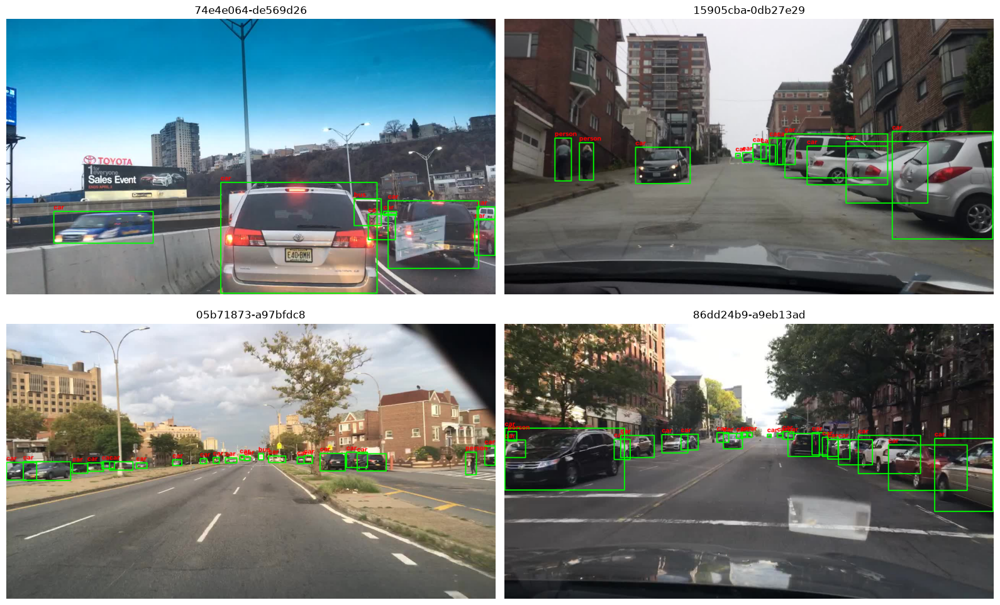

In [41]:

# Visual inspection of YOLO annotations

import cv2
import matplotlib.pyplot as plt
import random

CLASS_NAMES = {
    0: "car",
    1: "person",
    2: "bus"
}

random.seed(SEED)

sample_images = random.sample(
    list((IMAGE_ROOT / "baseline_train").glob("*.jpg")),
    4
)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, image_path in zip(axes.flatten(), sample_images):

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    height, width = image.shape[:2]

    label_path = (
        LABEL_ROOT / "baseline_train" /
        f"{image_path.stem}.txt"
    )

    for line in label_path.read_text(
        encoding="utf-8"
    ).splitlines():

        class_id, x_center, y_center, box_width, box_height = (
            map(float, line.split())
        )

        x_center *= width
        y_center *= height
        box_width *= width
        box_height *= height

        x1 = int(x_center - box_width / 2)
        y1 = int(y_center - box_height / 2)
        x2 = int(x_center + box_width / 2)
        y2 = int(y_center + box_height / 2)

        class_name = CLASS_NAMES[int(class_id)]

        cv2.rectangle(
            image, (x1, y1), (x2, y2),
            (0, 255, 0), 2
        )

        cv2.putText(
            image, class_name,
            (x1, max(y1 - 5, 15)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6, (255, 0, 0), 2
        )

    ax.imshow(image)
    ax.set_title(image_path.stem)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [42]:
import ultralytics
import torch

print("Ultralytics version:", ultralytics.__version__)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )

Ultralytics version: 8.4.216
PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
GPU memory: 8.0 GB


In [43]:

from ultralytics import YOLO
import torch

# Load pretrained models
yolo11 = YOLO("yolo11s.pt")
yolo26 = YOLO("yolo26s.pt")

# Inspect model information
print("\nYOLO11s")
yolo11.info()

print("\nYOLO26s")
yolo26.info()

print("\nBoth pretrained models loaded successfully.")



YOLO11s
YOLO11s summary: 181 layers, 9,458,752 parameters, 0 gradients, 21.8 GFLOPs

YOLO26s
YOLO26s summary: 260 layers, 10,009,784 parameters, 0 gradients, 23.1 GFLOPs

Both pretrained models loaded successfully.


In [44]:
print("YOLO11s pretrained classes:")
print(yolo11.names)

print("\nYOLO26s pretrained classes:")
print(yolo26.names)

print("\nNightSight target classes:")
print(CLASS_MAPPING)

YOLO11s pretrained classes:
{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 6

In [45]:
from ultralytics.data.utils import check_det_dataset

dataset_info = check_det_dataset(str(BASELINE_YAML_PATH))

print("Dataset path:", dataset_info["path"])
print("Training path:", dataset_info["train"])
print("Validation path:", dataset_info["val"])
print("Number of classes:", dataset_info["nc"])
print("Class names:", dataset_info["names"])

assert dataset_info["nc"] == 3
assert dataset_info["names"] == {
    0: "car",
    1: "person",
    2: "bus"
}

print("\nDataset configuration verified.")

Dataset path: C:\CH\NightSight\data\processed\nightsight_10k
Training path: C:\CH\NightSight\data\processed\nightsight_10k\images\baseline_train
Validation path: C:\CH\NightSight\data\processed\nightsight_10k\images\validation
Number of classes: 3
Class names: {0: 'car', 1: 'person', 2: 'bus'}

Dataset configuration verified.


In [46]:

# NightSight - Controlled YOLO training configuration

TRAIN_CONFIG = {
    "data": str(BASELINE_YAML_PATH),
    "epochs": 50,
    "imgsz": 640,
    "batch": 8,
    "device": 0,
    "workers": 4,
    "optimizer": "AdamW",
    "lr0": 0.001,
    "patience": 10,
    "seed": 42,
    "deterministic": True,
    "amp": True,
    "pretrained": True,
    "plots": True,
    "save": True,
    "exist_ok": False,
    "verbose": True
}

print("NightSight training configuration:")
for key, value in TRAIN_CONFIG.items():
    print(f"{key}: {value}")


NightSight training configuration:
data: c:\CH\NightSight\data\processed\nightsight_10k\bdd_daytime.yaml
epochs: 50
imgsz: 640
batch: 8
device: 0
workers: 4
optimizer: AdamW
lr0: 0.001
patience: 10
seed: 42
deterministic: True
amp: True
pretrained: True
plots: True
save: True
exist_ok: False
verbose: True


In [47]:

# NightSight - YOLO11s daytime baseline training

from ultralytics import YOLO
from pathlib import Path

yolo11_train = YOLO("yolo11s.pt")

YOLO11_PROJECT = PROJECT_ROOT / "experiments" / "runs"
YOLO11_NAME = "yolo11s_daytime_10k"

yolo11_results = yolo11_train.train(
    **TRAIN_CONFIG,
    project=str(YOLO11_PROJECT),
    name=YOLO11_NAME
)

YOLO11_BEST = (
    YOLO11_PROJECT / YOLO11_NAME / "weights" / "best.pt"
)

print("\nYOLO11s training completed.")
print("Best checkpoint:", YOLO11_BEST)
print("Checkpoint exists:", YOLO11_BEST.exists())


Ultralytics 8.4.216  Python-3.11.9 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\CH\NightSight\data\processed\nightsight_10k\bdd_daytime.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=y

In [48]:
import pandas as pd

YOLO11_RESULTS = (
    YOLO11_PROJECT / YOLO11_NAME / "results.csv"
)

results_df = pd.read_csv(YOLO11_RESULTS)
results_df.columns = results_df.columns.str.strip()

# Find the best epoch using validation mAP50-95
map_column = "metrics/mAP50-95(B)"
best_index = results_df[map_column].idxmax()
best_row = results_df.loc[best_index]

metrics = {
    "Best epoch": int(best_index + 1),
    "Precision": best_row["metrics/precision(B)"],
    "Recall": best_row["metrics/recall(B)"],
    "mAP50": best_row["metrics/mAP50(B)"],
    "mAP50-95": best_row["metrics/mAP50-95(B)"],
    "Training box loss": best_row["train/box_loss"],
    "Validation box loss": best_row["val/box_loss"]
}

display(pd.DataFrame(
    metrics.items(),
    columns=["Metric", "Value"]
))

print("\nTotal epochs completed:", len(results_df))
print("Best checkpoint exists:", YOLO11_BEST.exists())

,Metric,Value
0,Best epoch,37.00000
1,Precision,0.64237
2,Recall,0.45410
3,mAP50,0.48971
4,mAP50-95,0.28769
5,Training box loss,1.15673
6,Validation box loss,1.57824



Total epochs completed: 47
Best checkpoint exists: True


In [50]:

# NightSight - YOLO11s held-out nighttime evaluation

import yaml
from ultralytics import YOLO

# Create a separate evaluation configuration
evaluation_yaml = {
    "path": str(OUTPUT_DIR.resolve()),
    "train": "images/baseline_train",
    "val": "images/final_evaluation",
    "names": {
        0: "car",
        1: "person",
        2: "bus"
    }
}

EVALUATION_YAML_PATH = OUTPUT_DIR / "bdd_final_evaluation.yaml"

with open(EVALUATION_YAML_PATH, "w", encoding="utf-8") as f:
    yaml.safe_dump(evaluation_yaml, f, sort_keys=False)

# Load the trained YOLO11s checkpoint
final_model = YOLO(str(YOLO11_BEST))

# Evaluate on the held-out nighttime images
final_metrics = final_model.val(
    data=str(EVALUATION_YAML_PATH),
    imgsz=640,
    batch=8,
    device=0,
    workers=4,
    plots=True,
    project=str(YOLO11_PROJECT),
    name="yolo11s_final_evaluation",
    exist_ok=False
)

print("\nNightSight held-out evaluation completed.")
print("Results directory:", final_metrics.save_dir)


Ultralytics 8.4.216  Python-3.11.9 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
YOLO11s summary (fused): 100 layers, 9,413,961 parameters, 0 gradients, 21.4 GFLOPs
WARNING val: Slow image access detected (ping: 0.3±0.1 ms, read: 33.1±42.5 MB/s, size: 41.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\CH\NightSight\data\processed\nightsight_10k\labels\final_evaluation... 1500 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1500/1500 636.2it/s 2.4s0.1s
val: New cache created: C:\CH\NightSight\data\processed\nightsight_10k\labels\final_evaluation.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 188/188 7.8it/s 24.2s<0.1s
                   all       1500      15298      0.594      0.419      0.466      0.259
                   car       1496      14001      0.661      0.563      0.613

In [51]:

# NightSight - Inspect previous adaptation experiments

from pathlib import Path
import pandas as pd

SEARCH_DIRS = [
    PROJECT_ROOT / "experiments" / "runs",
    PROJECT_ROOT / "runs"
]

adaptation_runs = []

for search_dir in SEARCH_DIRS:
    if not search_dir.exists():
        continue

    for results_file in search_dir.rglob("results.csv"):
        if "adaptation" in str(results_file.parent).lower():
            adaptation_runs.append(results_file)

print("Previous adaptation experiments found:", len(adaptation_runs))

for results_file in adaptation_runs:

    df = pd.read_csv(results_file)
    df.columns = df.columns.str.strip()

    map_col = "metrics/mAP50-95(B)"
    best_idx = df[map_col].idxmax()
    best = df.loc[best_idx]

    print("\nExperiment:", results_file.parent.name)
    print("Best epoch:", best_idx + 1)
    print("Epochs completed:", len(df))
    print("Precision:", round(best["metrics/precision(B)"], 5))
    print("Recall:", round(best["metrics/recall(B)"], 5))
    print("mAP50:", round(best["metrics/mAP50(B)"], 5))
    print("mAP50-95:", round(best[map_col], 5))


Previous adaptation experiments found: 2

Experiment: adaptation_lr_1e4
Best epoch: 10
Epochs completed: 10
Precision: 0.67775
Recall: 0.01844
mAP50: 0.00181
mAP50-95: 0.00039

Experiment: few_shot_adaptation
Best epoch: 10
Epochs completed: 10
Precision: 0.70262
Recall: 0.0282
mAP50: 0.01285
mAP50-95: 0.00322


In [52]:
# NightSight - Compare baseline and adaptation configurations

import yaml
import pandas as pd

RUN_ROOTS = [
    PROJECT_ROOT / "experiments" / "runs",
    PROJECT_ROOT / "runs" / "detect" / "experiments" / "runs"
]

run_names = [
    "yolo11s_daytime_10k",
    "few_shot_adaptation",
    "adaptation_lr_1e4"
]

config_rows = []

for root in RUN_ROOTS:
    if not root.exists():
        continue

    for run_name in run_names:
        args_path = root / run_name / "args.yaml"

        if not args_path.exists():
            continue

        with open(args_path, "r", encoding="utf-8") as f:
            args = yaml.safe_load(f)

        config_rows.append({
            "experiment": run_name,
            "model": args.get("model"),
            "epochs": args.get("epochs"),
            "batch": args.get("batch"),
            "imgsz": args.get("imgsz"),
            "optimizer": args.get("optimizer"),
            "lr0": args.get("lr0"),
            "lrf": args.get("lrf"),
            "freeze": args.get("freeze"),
            "mosaic": args.get("mosaic"),
            "mixup": args.get("mixup"),
            "close_mosaic": args.get("close_mosaic"),
            "pretrained": args.get("pretrained"),
            "data": args.get("data")
        })

if config_rows:
    display(pd.DataFrame(config_rows).set_index("experiment"))
else:
    print("No args.yaml files found. Check the experiment directories.")

,model,epochs,batch,imgsz,optimizer,lr0,lrf,freeze,mosaic,mixup,close_mosaic,pretrained,data
experiment,,,,,,,,,,,,,
yolo11s_daytime_10k,yolo11s.pt,50,8,640,AdamW,0.0010,0.01,None,1.0,0.0,10,True,c:\CH\NightSight\data\processed\nightsight_10k...
adaptation_lr_1e4,C:\CH\NightSight\runs\detect\experiments\runs\...,10,8,640,AdamW,0.0001,0.01,None,1.0,0.0,10,False,configs/nightsight_adaptation.yaml


In [53]:
# Locate all previous adaptation args.yaml files

for root in [
    PROJECT_ROOT / "runs",
    PROJECT_ROOT / "experiments"
]:
    if not root.exists():
        continue

    for args_path in root.rglob("args.yaml"):
        if "adaptation" not in str(args_path.parent).lower():
            continue

        print("\nExperiment:", args_path.parent)

        with open(args_path, "r", encoding="utf-8") as f:
            args = yaml.safe_load(f)

        for key in [
            "model", "epochs", "optimizer", "lr0",
            "pretrained", "data", "freeze",
            "mosaic", "mixup", "close_mosaic"
        ]:
            print(f"{key}: {args.get(key)}")


Experiment: c:\CH\NightSight\runs\detect\runs\nightsight\few_shot_adaptation
model: runs\detect\experiments\runs\baseline_daytime\weights\best.pt
epochs: 10
optimizer: auto
lr0: 0.01
pretrained: False
data: configs/nightsight_adaptation.yaml
freeze: None
mosaic: 1.0
mixup: 0.0
close_mosaic: 10

Experiment: c:\CH\NightSight\experiments\runs\adaptation_lr_1e4
model: C:\CH\NightSight\runs\detect\experiments\runs\baseline_daytime\weights\best.pt
epochs: 10
optimizer: AdamW
lr0: 0.0001
pretrained: False
data: configs/nightsight_adaptation.yaml
freeze: None
mosaic: 1.0
mixup: 0.0
close_mosaic: 10


In [54]:
from ultralytics import YOLO

adaptation_source = YOLO(str(YOLO11_BEST))

print("Checkpoint:", YOLO11_BEST)
print("Checkpoint exists:", YOLO11_BEST.exists())
print("Model classes:", adaptation_source.names)
print("Number of classes:", len(adaptation_source.names))

assert YOLO11_BEST.exists()
assert len(adaptation_source.names) == 3

print("\nYOLO11s adaptation starting checkpoint verified.")

Checkpoint: c:\CH\NightSight\experiments\runs\yolo11s_daytime_10k\weights\best.pt
Checkpoint exists: True
Model classes: {0: 'car', 1: 'person', 2: 'bus'}
Number of classes: 3

YOLO11s adaptation starting checkpoint verified.


In [55]:

# NightSight - Nighttime adaptation configuration

import yaml

adaptation_yaml = {
    "path": str(OUTPUT_DIR.resolve()),
    "train": "images/adaptation_train",
    "val": "images/validation",
    "names": {
        0: "car",
        1: "person",
        2: "bus"
    }
}

ADAPTATION_YAML_PATH = OUTPUT_DIR / "bdd_nighttime_adaptation.yaml"

with open(ADAPTATION_YAML_PATH, "w", encoding="utf-8") as f:
    yaml.safe_dump(
        adaptation_yaml,
        f,
        sort_keys=False
    )

print(ADAPTATION_YAML_PATH.read_text(encoding="utf-8"))
print("\nAdaptation configuration saved.")


path: C:\CH\NightSight\data\processed\nightsight_10k
train: images/adaptation_train
val: images/validation
names:
  0: car
  1: person
  2: bus


Adaptation configuration saved.


In [56]:

# NightSight - Nighttime adaptation training configuration

ADAPTATION_CONFIG = {
    "data": str(ADAPTATION_YAML_PATH),
    "epochs": 20,
    "imgsz": 640,
    "batch": 8,
    "device": 0,
    "workers": 4,
    "optimizer": "AdamW",
    "lr0": 0.0001,
    "lrf": 0.01,
    "patience": 8,
    "seed": 42,
    "deterministic": True,
    "amp": True,
    "pretrained": True,
    "mosaic": 0.0,
    "mixup": 0.0,
    "close_mosaic": 0,
    "plots": True,
    "save": True,
    "exist_ok": False,
    "verbose": True
}

print("Nighttime adaptation configuration:")

for key, value in ADAPTATION_CONFIG.items():
    print(f"{key}: {value}")


Nighttime adaptation configuration:
data: c:\CH\NightSight\data\processed\nightsight_10k\bdd_nighttime_adaptation.yaml
epochs: 20
imgsz: 640
batch: 8
device: 0
workers: 4
optimizer: AdamW
lr0: 0.0001
lrf: 0.01
patience: 8
seed: 42
deterministic: True
amp: True
pretrained: True
mosaic: 0.0
mixup: 0.0
close_mosaic: 0
plots: True
save: True
exist_ok: False
verbose: True


In [2]:

# ============================================================
# NightSight: YOLO11s Nighttime Domain Adaptation
# Self-contained training cell
# ============================================================

from pathlib import Path
from ultralytics import YOLO
import torch
import yaml

# 1. Project paths
PROJECT_ROOT = Path.cwd().parent

OUTPUT_DIR = (
    PROJECT_ROOT / "data" / "processed" / "nightsight_10k"
)

CHECKPOINT = (
    PROJECT_ROOT
    / "experiments" / "runs"
    / "yolo11s_daytime_10k"
    / "weights" / "best.pt"
)

ADAPTATION_YAML = (
    OUTPUT_DIR / "bdd_nighttime_adaptation.yaml"
)

RUN_PROJECT = PROJECT_ROOT / "experiments" / "runs"
RUN_NAME = "yolo11s_night_adaptation_10k"

# 2. Verify required files
assert CHECKPOINT.exists(), f"Checkpoint missing: {CHECKPOINT}"
assert ADAPTATION_YAML.exists(), f"Dataset YAML missing: {ADAPTATION_YAML}"

assert torch.cuda.is_available(), "CUDA GPU is not available."

# 3. Verify dataset configuration
with open(ADAPTATION_YAML, "r", encoding="utf-8") as f:
    dataset_config = yaml.safe_load(f)

assert dataset_config["names"] == {
    0: "car",
    1: "person",
    2: "bus"
}

# 4. Load the daytime-trained YOLO11s checkpoint
model = YOLO(str(CHECKPOINT))

assert len(model.names) == 3, "Unexpected model class count."

print("Starting checkpoint:", CHECKPOINT)
print("Classes:", model.names)
print("GPU:", torch.cuda.get_device_name(0))
print("Adaptation dataset:", ADAPTATION_YAML)

# 5. Nighttime adaptation configuration
ADAPTATION_CONFIG = {
    "data": str(ADAPTATION_YAML),
    "epochs": 20,
    "imgsz": 640,
    "batch": 8,
    "device": 0,
    "workers": 4,
    "optimizer": "AdamW",
    "lr0": 0.0001,
    "lrf": 0.01,
    "patience": 8,
    "seed": 42,
    "deterministic": True,
    "amp": True,
    "pretrained": True,
    "mosaic": 0.0,
    "mixup": 0.0,
    "close_mosaic": 0,
    "plots": True,
    "save": True,
    "exist_ok": False,
    "verbose": True
}

# 6. Train
results = model.train(
    **ADAPTATION_CONFIG,
    project=str(RUN_PROJECT),
    name=RUN_NAME
)

# 7. Verify saved checkpoint
ADAPTED_BEST = (
    RUN_PROJECT / RUN_NAME / "weights" / "best.pt"
)

print("\nNighttime adaptation finished.")
print("Best checkpoint:", ADAPTED_BEST)
print("Checkpoint exists:", ADAPTED_BEST.exists())

assert ADAPTED_BEST.exists()


Starting checkpoint: c:\CH\NightSight\experiments\runs\yolo11s_daytime_10k\weights\best.pt
Classes: {0: 'car', 1: 'person', 2: 'bus'}
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Adaptation dataset: c:\CH\NightSight\data\processed\nightsight_10k\bdd_nighttime_adaptation.yaml
Ultralytics 8.4.216  Python-3.11.9 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\CH\NightSight\data\processed\nightsight_10k\bdd_nighttime_adaptation.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5,

AssertionError: 

In [3]:

# NightSight - Locate completed adaptation checkpoint

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
RUN_ROOT = PROJECT_ROOT / "experiments" / "runs"

# Find all matching adaptation experiment directories
matching_runs = sorted(
    RUN_ROOT.glob("yolo11s_night_adaptation_10k*"),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

print("Matching experiment directories:", len(matching_runs))

for run_dir in matching_runs:
    best = run_dir / "weights" / "best.pt"
    last = run_dir / "weights" / "last.pt"

    print("\nExperiment:", run_dir.name)
    print("Best checkpoint exists:", best.exists())
    print("Last checkpoint exists:", last.exists())

    if best.exists():
        ADAPTED_BEST = best
        print("\nVerified best checkpoint:", ADAPTED_BEST)
        break

assert "ADAPTED_BEST" in globals(), "No best.pt checkpoint found."

print("\nNighttime adaptation checkpoint verified.")


Matching experiment directories: 2

Experiment: yolo11s_night_adaptation_10k-2
Best checkpoint exists: True
Last checkpoint exists: True

Verified best checkpoint: c:\CH\NightSight\experiments\runs\yolo11s_night_adaptation_10k-2\weights\best.pt

Nighttime adaptation checkpoint verified.


In [4]:

# NightSight - Extract nighttime adaptation metrics

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent

RESULTS_CSV = (
    PROJECT_ROOT / "experiments" / "runs"
    / "yolo11s_night_adaptation_10k-2"
    / "results.csv"
)

assert RESULTS_CSV.exists(), f"Missing results file: {RESULTS_CSV}"

df = pd.read_csv(RESULTS_CSV)
df.columns = df.columns.str.strip()

metric_col = "metrics/mAP50-95(B)"
best_idx = df[metric_col].idxmax()
best = df.loc[best_idx]

summary = {
    "Best epoch": int(best_idx + 1),
    "Epochs completed": len(df),
    "Precision": best["metrics/precision(B)"],
    "Recall": best["metrics/recall(B)"],
    "mAP50": best["metrics/mAP50(B)"],
    "mAP50-95": best["metrics/mAP50-95(B)"]
}

display(pd.DataFrame(
    summary.items(),
    columns=["Metric", "Value"]
))

print("\nAdaptation training metrics extracted.")


,Metric,Value
0,Best epoch,16.00000
1,Epochs completed,20.00000
2,Precision,0.62674
3,Recall,0.50074
4,mAP50,0.55803
5,mAP50-95,0.33329



Adaptation training metrics extracted.


In [5]:

# NightSight - Final evaluation of nighttime-adapted YOLO11s

from pathlib import Path
from ultralytics import YOLO
import yaml
import torch

# Project paths
PROJECT_ROOT = Path.cwd().parent
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "nightsight_10k"

ADAPTED_CHECKPOINT = (
    PROJECT_ROOT / "experiments" / "runs"
    / "yolo11s_night_adaptation_10k-2"
    / "weights" / "best.pt"
)

assert ADAPTED_CHECKPOINT.exists(), "Adapted checkpoint not found."
assert torch.cuda.is_available(), "CUDA GPU unavailable."

# Create held-out evaluation configuration
evaluation_config = {
    "path": str(OUTPUT_DIR.resolve()),
    "train": "images/baseline_train",
    "val": "images/final_evaluation",
    "names": {
        0: "car",
        1: "person",
        2: "bus"
    }
}

EVALUATION_YAML = OUTPUT_DIR / "bdd_final_evaluation.yaml"

with open(EVALUATION_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(evaluation_config, f, sort_keys=False)

# Load adapted model
adapted_model = YOLO(str(ADAPTED_CHECKPOINT))

print("Adapted checkpoint:", ADAPTED_CHECKPOINT)
print("GPU:", torch.cuda.get_device_name(0))
print("Evaluation images: 1,500 nighttime images")

# Evaluate without training or changing model weights
evaluation_results = adapted_model.val(
    data=str(EVALUATION_YAML),
    imgsz=640,
    batch=8,
    device=0,
    workers=4,
    plots=True,
    project=str(PROJECT_ROOT / "experiments" / "runs"),
    name="yolo11s_adapted_final_evaluation",
    exist_ok=False
)

print("\nAdapted model held-out evaluation completed.")
print("Results directory:", evaluation_results.save_dir)


Adapted checkpoint: c:\CH\NightSight\experiments\runs\yolo11s_night_adaptation_10k-2\weights\best.pt
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Evaluation images: 1,500 nighttime images
Ultralytics 8.4.216  Python-3.11.9 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
YOLO11s summary (fused): 100 layers, 9,413,961 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.2±0.1 ms, read: 129.1±36.1 MB/s, size: 42.5 KB)
val: Scanning C:\CH\NightSight\data\processed\nightsight_10k\labels\final_evaluation.cache... 1500 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1500/1500  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 188/188 10.6it/s 17.8s0.0s
                   all       1500      15298      0.611      0.504      0.546      0.318
                   car       1496      14001      0.767      0.613      0.706      0.392
                person        322       1180      0.711      0.36

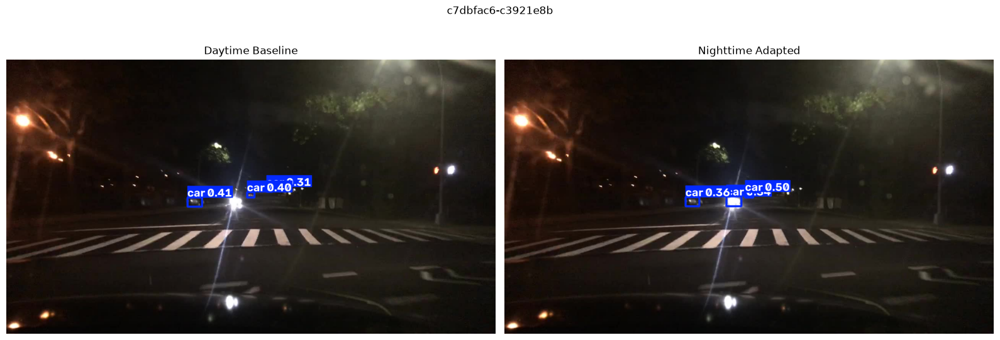

Saved: c:\CH\NightSight\results\plots\baseline_vs_adapted\c7dbfac6-c3921e8b_comparison.png


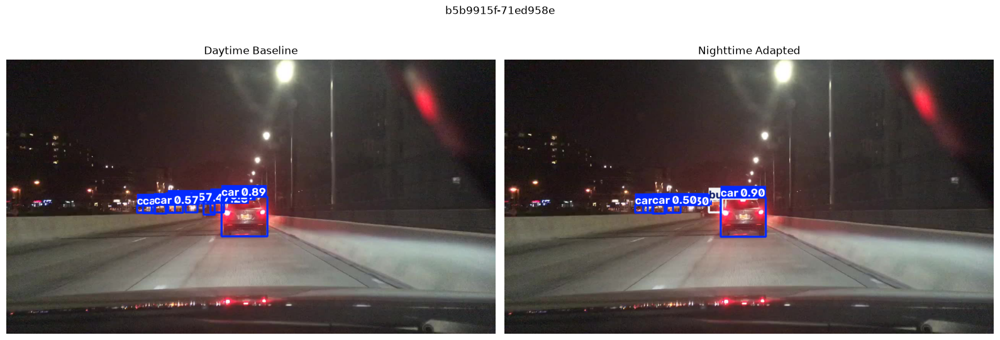

Saved: c:\CH\NightSight\results\plots\baseline_vs_adapted\b5b9915f-71ed958e_comparison.png


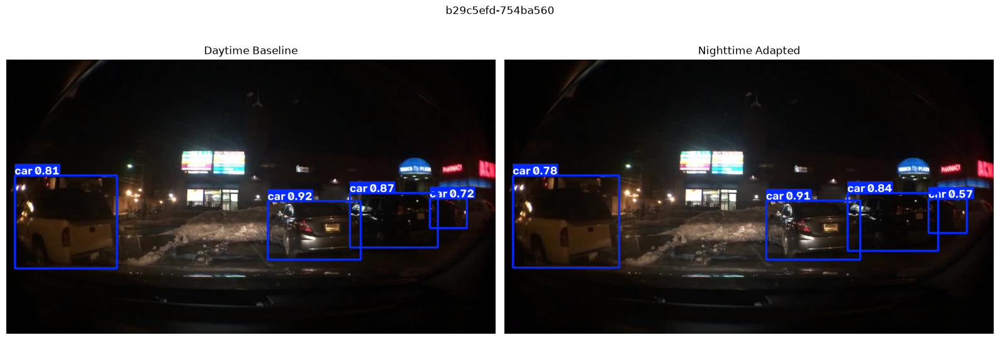

Saved: c:\CH\NightSight\results\plots\baseline_vs_adapted\b29c5efd-754ba560_comparison.png


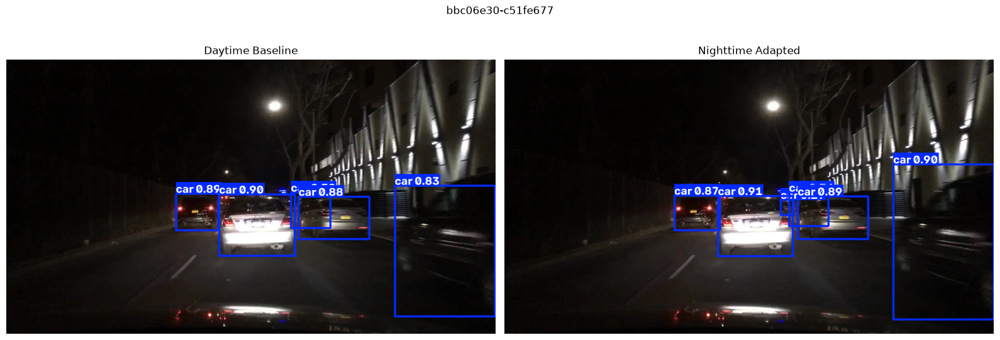

Saved: c:\CH\NightSight\results\plots\baseline_vs_adapted\bbc06e30-c51fe677_comparison.png

Visual comparison completed.
Images examined: 4
Output directory: c:\CH\NightSight\results\plots\baseline_vs_adapted


In [6]:

# NightSight - Baseline vs Adapted Failure-Case Analysis

from pathlib import Path
from ultralytics import YOLO
import pandas as pd
import matplotlib.pyplot as plt
import random
import cv2

# Project paths
PROJECT_ROOT = Path.cwd().parent
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "nightsight_10k"

BASELINE_CHECKPOINT = (
    PROJECT_ROOT / "experiments" / "runs"
    / "yolo11s_daytime_10k" / "weights" / "best.pt"
)

ADAPTED_CHECKPOINT = (
    PROJECT_ROOT / "experiments" / "runs"
    / "yolo11s_night_adaptation_10k-2"
    / "weights" / "best.pt"
)

IMAGE_DIR = OUTPUT_DIR / "images" / "final_evaluation"
LABEL_DIR = OUTPUT_DIR / "labels" / "final_evaluation"

VIS_DIR = (
    PROJECT_ROOT / "results" / "plots"
    / "baseline_vs_adapted"
)
VIS_DIR.mkdir(parents=True, exist_ok=True)

assert BASELINE_CHECKPOINT.exists()
assert ADAPTED_CHECKPOINT.exists()
assert IMAGE_DIR.exists()

# Load models
baseline_model = YOLO(str(BASELINE_CHECKPOINT))
adapted_model = YOLO(str(ADAPTED_CHECKPOINT))

CLASS_NAMES = {
    0: "car",
    1: "person",
    2: "bus"
}

# Select four reproducible evaluation images
random.seed(42)

image_files = sorted(IMAGE_DIR.glob("*.jpg"))
sample_images = random.sample(image_files, min(4, len(image_files)))

# Generate comparison
for image_path in sample_images:

    baseline_result = baseline_model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    adapted_result = adapted_model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    baseline_image = cv2.cvtColor(
        baseline_result.plot(),
        cv2.COLOR_BGR2RGB
    )

    adapted_image = cv2.cvtColor(
        adapted_result.plot(),
        cv2.COLOR_BGR2RGB
    )

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    axes[0].imshow(baseline_image)
    axes[0].set_title("Daytime Baseline")
    axes[0].axis("off")

    axes[1].imshow(adapted_image)
    axes[1].set_title("Nighttime Adapted")
    axes[1].axis("off")

    fig.suptitle(image_path.stem)
    plt.tight_layout()

    save_path = VIS_DIR / f"{image_path.stem}_comparison.png"
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Saved:", save_path)

print("\nVisual comparison completed.")
print("Images examined:", len(sample_images))
print("Output directory:", VIS_DIR)


# NightSight – Final Results

**YOLO11s | 4,000 daytime training | 3,000 nighttime adaptation | 1,500 held-out nighttime evaluation images**

## 1. Nighttime Predictions

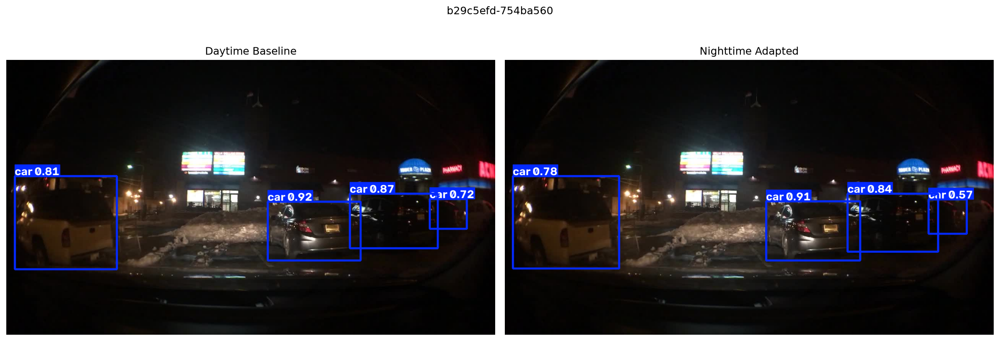

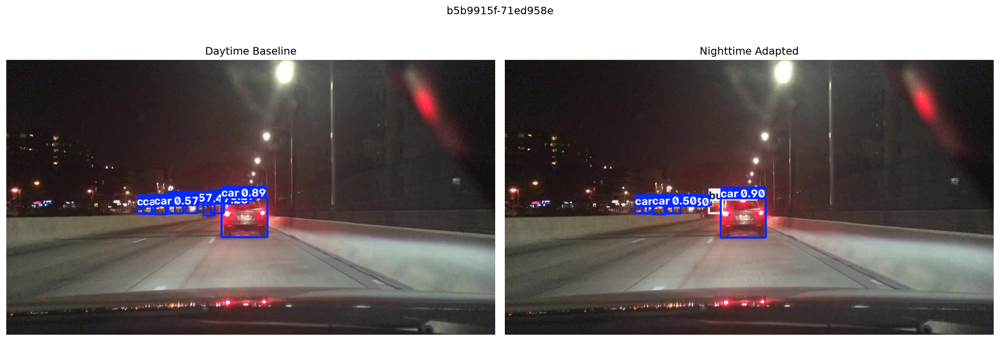

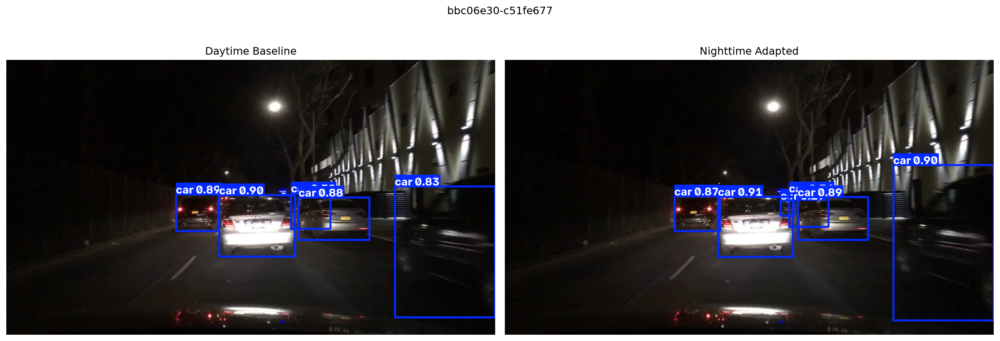

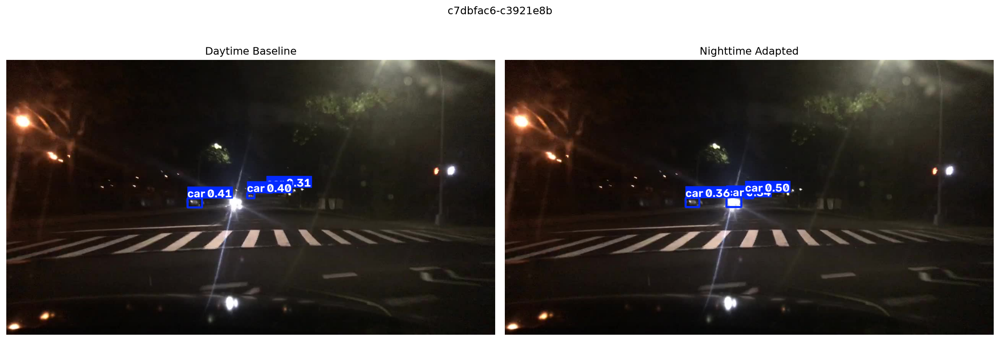

## 2. Overall Evaluation

Metric,Baseline,Adapted,Change_pp
Precision,0.594,0.611,+1.7
Recall,0.419,0.504,+8.5
mAP50,0.466,0.546,+8.0
mAP50-95,0.259,0.318,+5.9


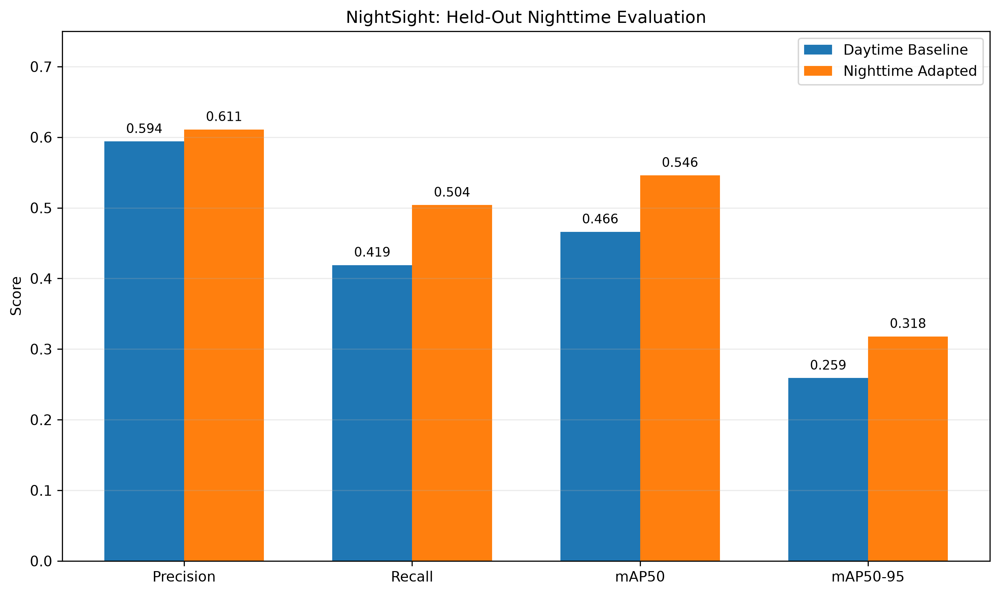

## 3. Class-wise mAP@50

Category,Baseline,Adapted,Change_pp
Car,0.613,0.706,+9.3
Person,0.425,0.486,+6.1
Bus,0.360,0.447,+8.7



## Conclusion
Nighttime adaptation improved all four aggregate metrics on the held-out
nighttime evaluation subset. Car, person, and bus mAP@50 also improved.


Displayed 4 prediction comparisons.
Results loaded from saved files.


In [11]:

# NightSight - Compact Results Dashboard

from pathlib import Path
import pandas as pd
from IPython.display import display, Image, Markdown

# Locate project
ROOT = next(
    (p for p in [Path.cwd(), Path.cwd().parent]
     if (p / "results/final_comparison/held_out_evaluation_comparison.csv").exists()),
    None
)
assert ROOT is not None, "NightSight project not found."

# Load saved results
RESULTS = ROOT / "results/final_comparison"
PREDICTIONS = ROOT / "results/plots/baseline_vs_adapted"
df = pd.read_csv(RESULTS / "held_out_evaluation_comparison.csv")

display(Markdown("# NightSight – Final Results"))
display(Markdown(
    "**YOLO11s | 4,000 daytime training | 3,000 nighttime adaptation | "
    "1,500 held-out nighttime evaluation images**"
))

# Prediction comparisons
display(Markdown("## 1. Nighttime Predictions"))
images = sorted(PREDICTIONS.glob("*_comparison.png"))
for path in images:
    display(Image(filename=str(path), width=850))

# Overall metrics
display(Markdown("## 2. Overall Evaluation"))
overall = df[df.Category == "Overall"][
    ["Metric", "Baseline", "Adapted", "Change_pp"]
]
display(overall.style.format({
    "Baseline": "{:.3f}",
    "Adapted": "{:.3f}",
    "Change_pp": "{:+.1f}"
}).hide(axis="index"))

plot = RESULTS / "overall_metric_comparison.png"
if plot.exists():
    display(Image(filename=str(plot), width=850))

# Class-wise mAP50
display(Markdown("## 3. Class-wise mAP@50"))
classes = df[
    (df.Metric == "mAP50") & (df.Category != "Overall")
][["Category", "Baseline", "Adapted", "Change_pp"]]

display(classes.style.format({
    "Baseline": "{:.3f}",
    "Adapted": "{:.3f}",
    "Change_pp": "{:+.1f}"
}).hide(axis="index"))

display(Markdown("""
## Conclusion
Nighttime adaptation improved all four aggregate metrics on the held-out
nighttime evaluation subset. Car, person, and bus mAP@50 also improved.
"""))

print(f"Displayed {len(images)} prediction comparisons.")
print("Results loaded from saved files.")


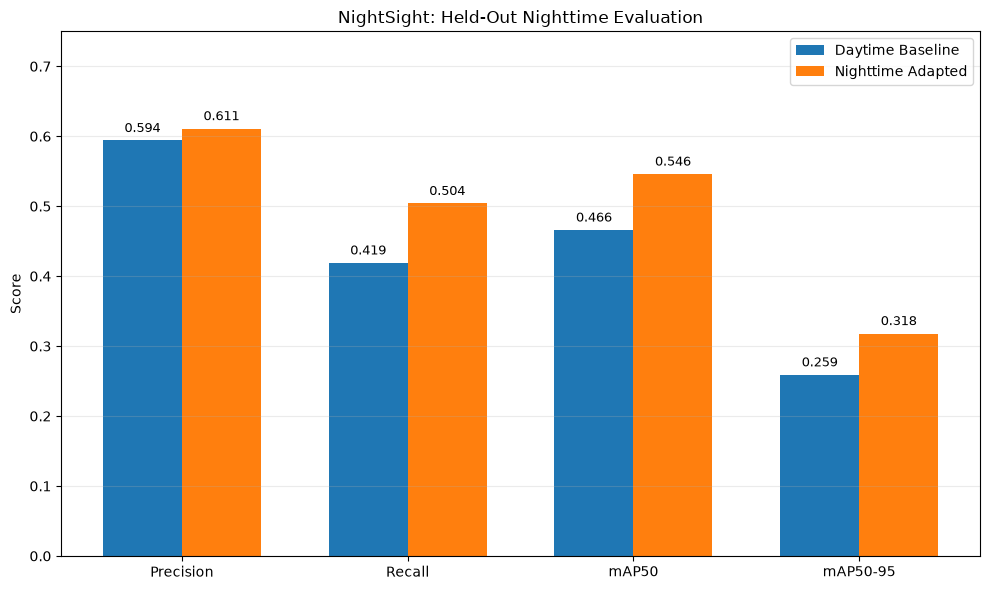

OVERALL HELD-OUT RESULTS
   Metric  Baseline  Adapted  Change_pp
Precision     0.594    0.611        1.7
   Recall     0.419    0.504        8.5
    mAP50     0.466    0.546        8.0
 mAP50-95     0.259    0.318        5.9

CLASS-WISE mAP50 RESULTS
Category  Baseline  Adapted  Change_pp
 Overall     0.466    0.546        8.0
     Car     0.613    0.706        9.3
  Person     0.425    0.486        6.1
     Bus     0.360    0.447        8.7

Saved:
c:\CH\NightSight\results\final_comparison\held_out_evaluation_comparison.csv
c:\CH\NightSight\results\final_comparison\overall_metric_comparison.png


In [8]:

# NightSight - Final Held-Out Evaluation Comparison

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Locate project root
CANDIDATES = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next(
    (p for p in CANDIDATES if (p / "data/processed/nightsight_10k").exists()),
    None
)
assert PROJECT_ROOT is not None, "Could not locate NightSight project root."

OUTPUT_DIR = PROJECT_ROOT / "results" / "final_comparison"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Metrics from the held-out evaluation (1,500 nighttime images)
results = [
    ["Overall", "Precision", 0.594, 0.611],
    ["Overall", "Recall", 0.419, 0.504],
    ["Overall", "mAP50", 0.466, 0.546],
    ["Overall", "mAP50-95", 0.259, 0.318],
    ["Car", "Precision", 0.661, 0.767],
    ["Car", "Recall", 0.563, 0.613],
    ["Car", "mAP50", 0.613, 0.706],
    ["Car", "mAP50-95", 0.331, 0.392],
    ["Person", "Precision", 0.635, 0.711],
    ["Person", "Recall", 0.352, 0.366],
    ["Person", "mAP50", 0.425, 0.486],
    ["Person", "mAP50-95", 0.191, 0.221],
    ["Bus", "Precision", 0.485, 0.354],
    ["Bus", "Recall", 0.342, 0.533],
    ["Bus", "mAP50", 0.360, 0.447],
    ["Bus", "mAP50-95", 0.256, 0.341],
]

df = pd.DataFrame(
    results,
    columns=["Category", "Metric", "Baseline", "Adapted"]
)

df["Change"] = (df["Adapted"] - df["Baseline"]).round(3)
df["Change_pp"] = (df["Change"] * 100).round(1)

csv_path = OUTPUT_DIR / "held_out_evaluation_comparison.csv"
df.to_csv(csv_path, index=False)

# Plot the four overall metrics
overall = df[df["Category"] == "Overall"].copy()

x = np.arange(len(overall))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(x - width / 2, overall["Baseline"], width, label="Daytime Baseline")
ax.bar(x + width / 2, overall["Adapted"], width, label="Nighttime Adapted")

ax.set_ylabel("Score")
ax.set_title("NightSight: Held-Out Nighttime Evaluation")
ax.set_xticks(x)
ax.set_xticklabels(overall["Metric"])
ax.set_ylim(0, 0.75)
ax.legend()
ax.grid(axis="y", alpha=0.25)

for i, row in enumerate(overall.itertuples()):
    ax.text(i - width / 2, row.Baseline + 0.012, f"{row.Baseline:.3f}",
            ha="center", fontsize=9)
    ax.text(i + width / 2, row.Adapted + 0.012, f"{row.Adapted:.3f}",
            ha="center", fontsize=9)

plt.tight_layout()

plot_path = OUTPUT_DIR / "overall_metric_comparison.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("OVERALL HELD-OUT RESULTS")
print(overall[["Metric", "Baseline", "Adapted", "Change_pp"]].to_string(index=False))

print("\nCLASS-WISE mAP50 RESULTS")
print(
    df[df["Metric"] == "mAP50"]
    [["Category", "Baseline", "Adapted", "Change_pp"]]
    .to_string(index=False)
)

print("\nSaved:")
print(csv_path)
print(plot_path)


# NightSight – Final Results

**YOLO11s | 4,000 daytime training | 3,000 nighttime adaptation | 1,500 held-out nighttime evaluation images**

## 1. Nighttime Predictions

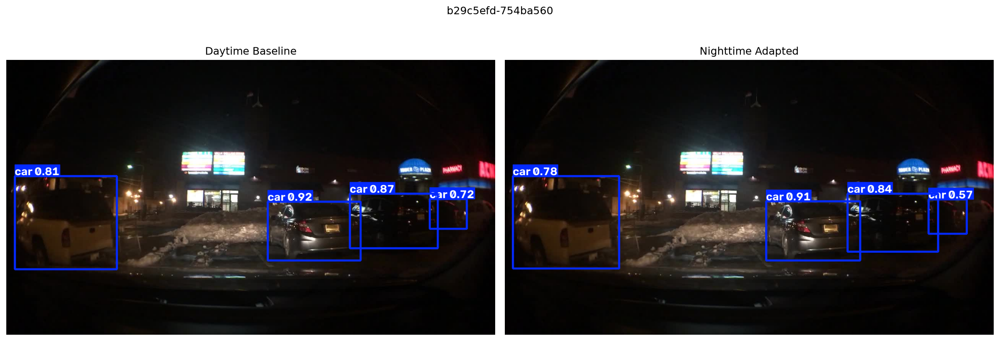

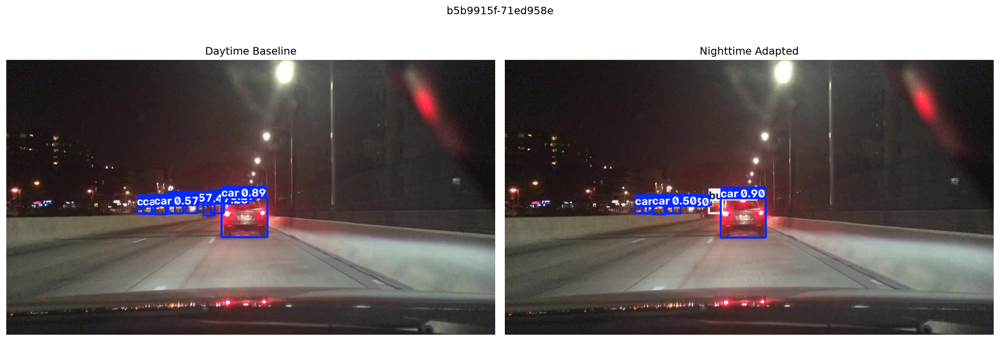

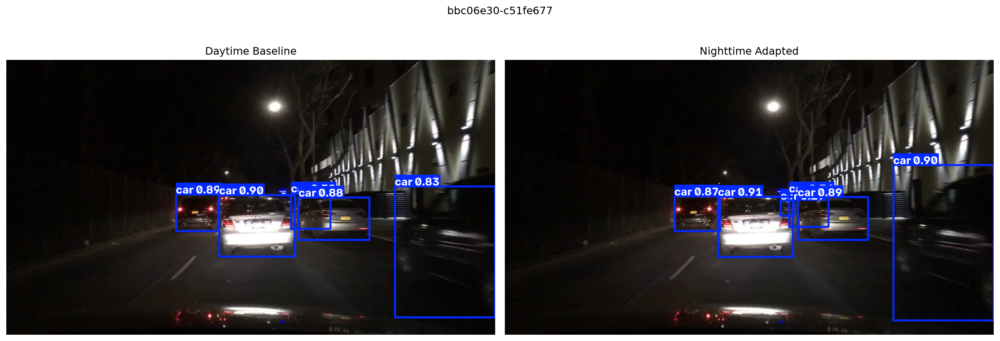

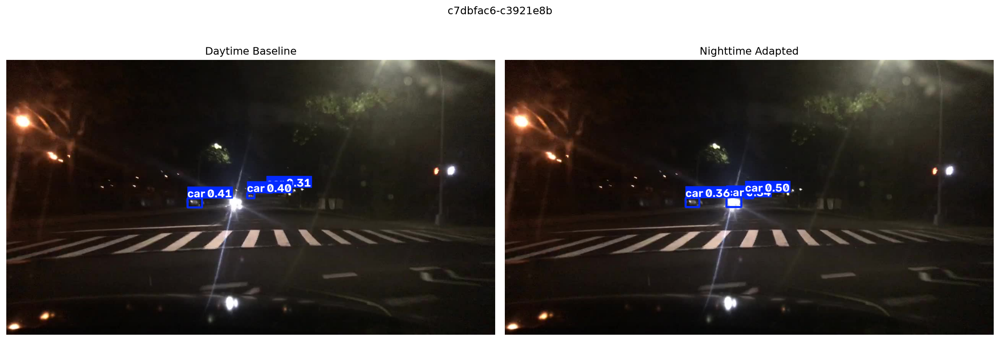

## 2. Overall Evaluation

Metric,Baseline,Adapted,Change_pp
Precision,0.594,0.611,+1.7
Recall,0.419,0.504,+8.5
mAP50,0.466,0.546,+8.0
mAP50-95,0.259,0.318,+5.9


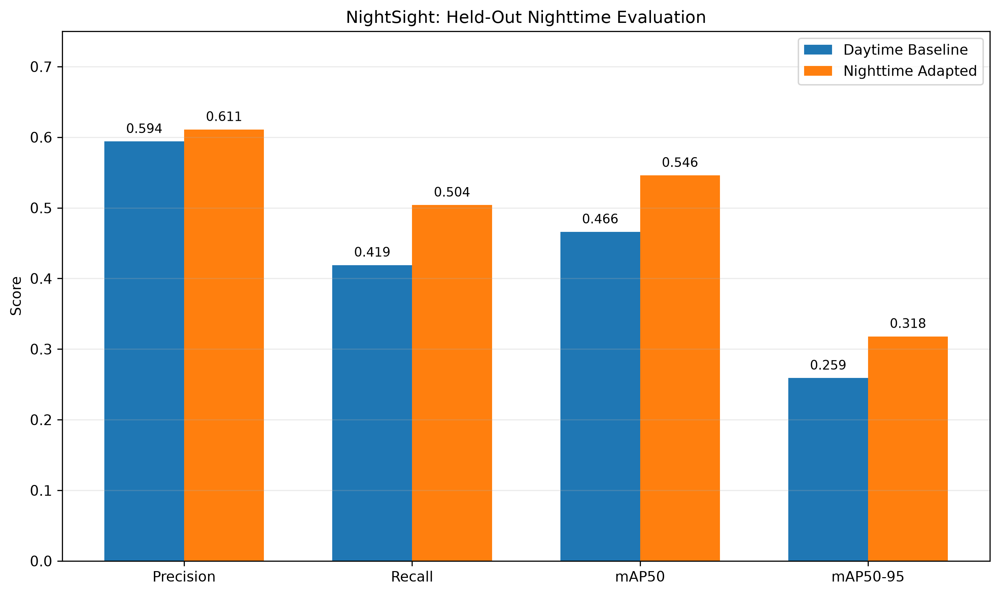

## 3. Class-wise mAP@50

Category,Baseline,Adapted,Change_pp
Car,0.613,0.706,+9.3
Person,0.425,0.486,+6.1
Bus,0.360,0.447,+8.7



## Conclusion
Nighttime adaptation improved all four aggregate metrics on the held-out
nighttime evaluation subset. Car, person, and bus mAP@50 also improved.


Displayed 4 prediction comparisons.
Results loaded from saved files.


In [14]:

# NightSight - Compact Results Dashboard

from pathlib import Path
import pandas as pd
from IPython.display import display, Image, Markdown

# Locate project
ROOT = next(
    (p for p in [Path.cwd(), Path.cwd().parent]
     if (p / "results/final_comparison/held_out_evaluation_comparison.csv").exists()),
    None
)
assert ROOT is not None, "NightSight project not found."

# Load saved results
RESULTS = ROOT / "results/final_comparison"
PREDICTIONS = ROOT / "results/plots/baseline_vs_adapted"
df = pd.read_csv(RESULTS / "held_out_evaluation_comparison.csv")

display(Markdown("# NightSight – Final Results"))
display(Markdown(
    "**YOLO11s | 4,000 daytime training | 3,000 nighttime adaptation | "
    "1,500 held-out nighttime evaluation images**"
))

# Prediction comparisons
display(Markdown("## 1. Nighttime Predictions"))
images = sorted(PREDICTIONS.glob("*_comparison.png"))
for path in images:
    display(Image(filename=str(path), width=850))

# Overall metrics
display(Markdown("## 2. Overall Evaluation"))
overall = df[df.Category == "Overall"][
    ["Metric", "Baseline", "Adapted", "Change_pp"]
]
display(overall.style.format({
    "Baseline": "{:.3f}",
    "Adapted": "{:.3f}",
    "Change_pp": "{:+.1f}"
}).hide(axis="index"))

plot = RESULTS / "overall_metric_comparison.png"
if plot.exists():
    display(Image(filename=str(plot), width=850))

# Class-wise mAP50
display(Markdown("## 3. Class-wise mAP@50"))
classes = df[
    (df.Metric == "mAP50") & (df.Category != "Overall")
][["Category", "Baseline", "Adapted", "Change_pp"]]

display(classes.style.format({
    "Baseline": "{:.3f}",
    "Adapted": "{:.3f}",
    "Change_pp": "{:+.1f}"
}).hide(axis="index"))

display(Markdown("""
## Conclusion
Nighttime adaptation improved all four aggregate metrics on the held-out
nighttime evaluation subset. Car, person, and bus mAP@50 also improved.
"""))

print(f"Displayed {len(images)} prediction comparisons.")
print("Results loaded from saved files.")


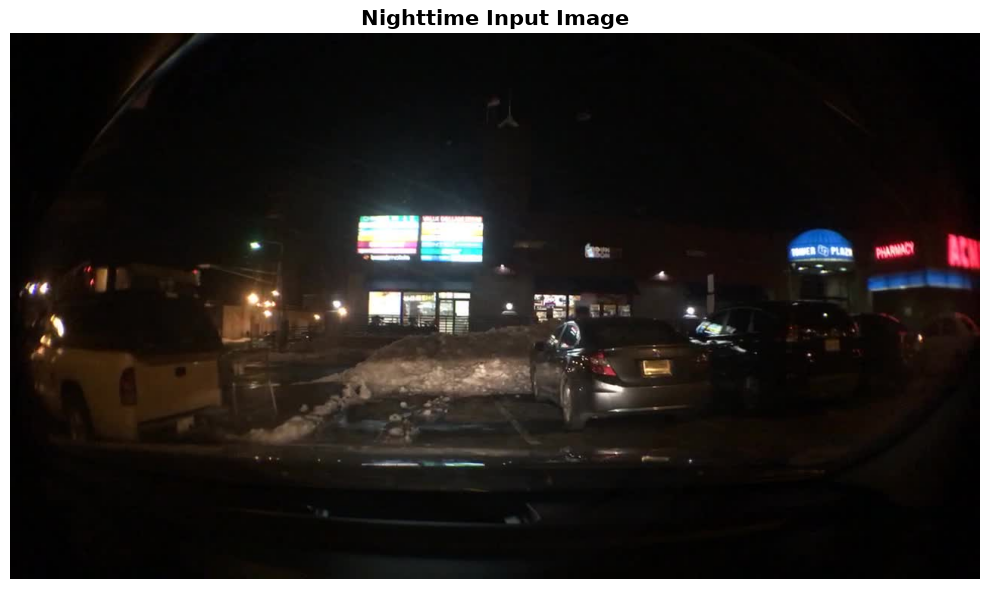

Saved: c:\CH\NightSight\results\poster_figures\Figure_1_Nighttime_Input.png


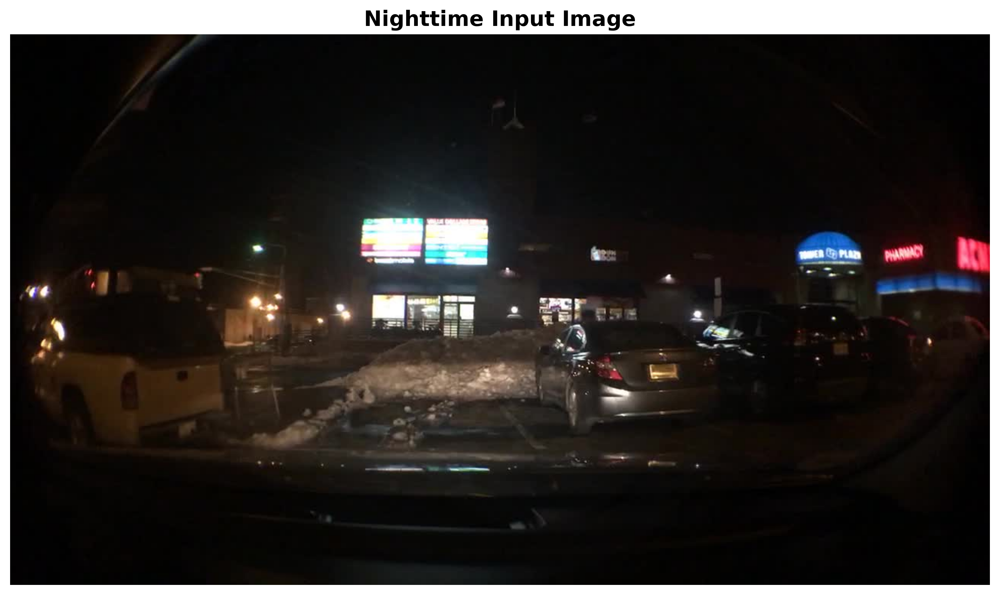

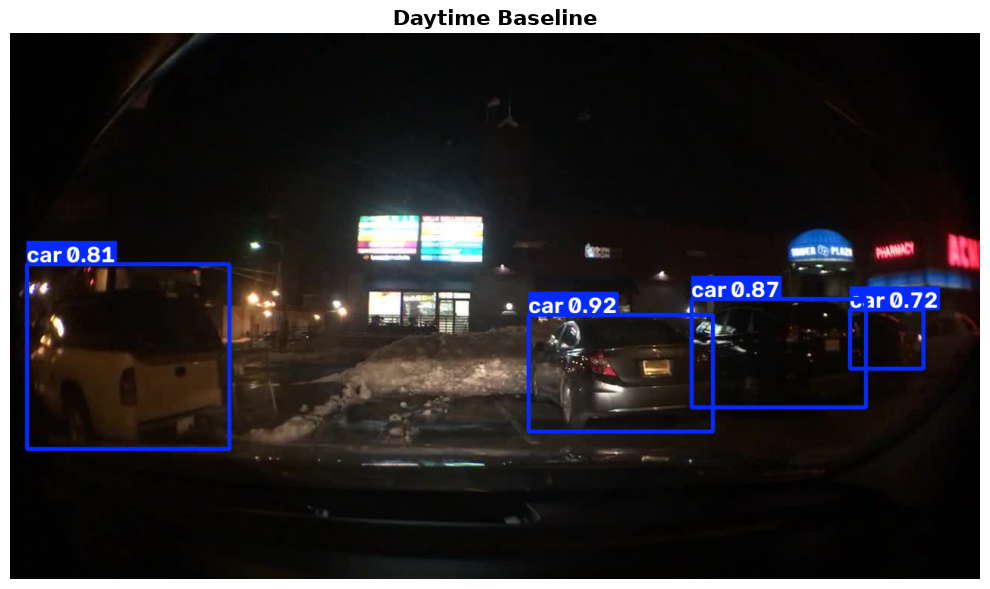

Saved: c:\CH\NightSight\results\poster_figures\Figure_2_Daytime_Baseline.png


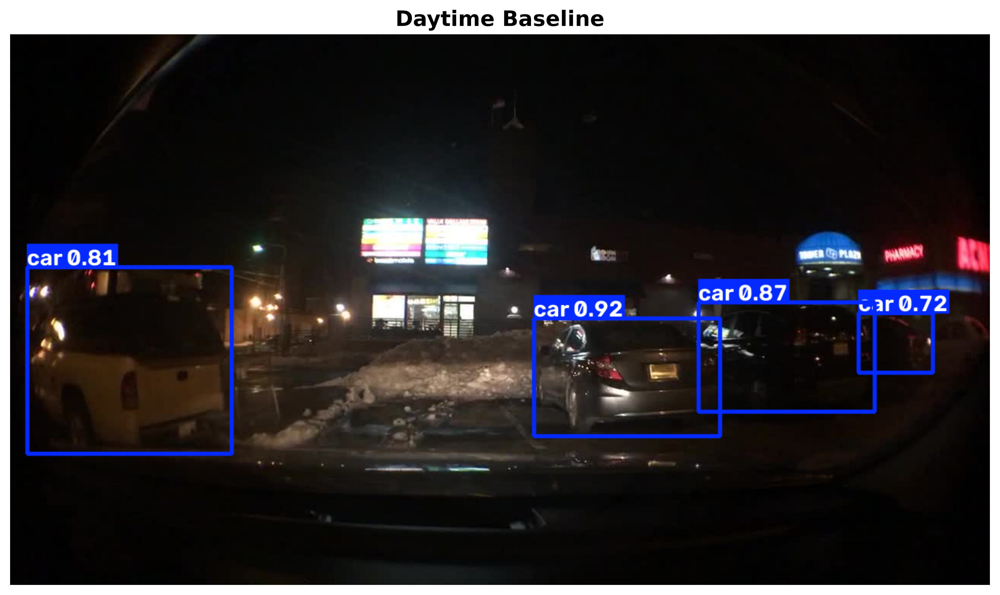

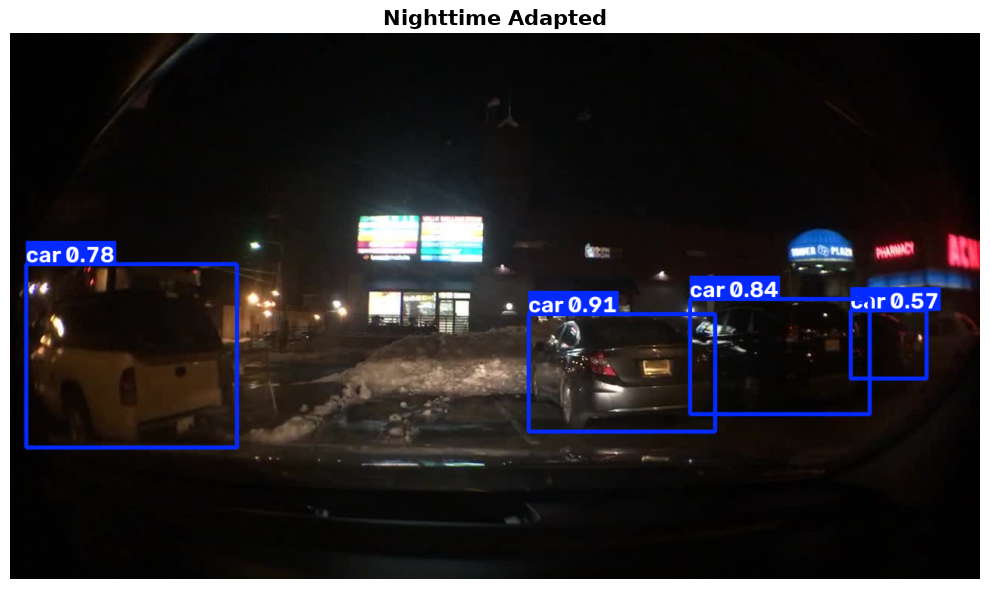

Saved: c:\CH\NightSight\results\poster_figures\Figure_3_Nighttime_Adapted.png


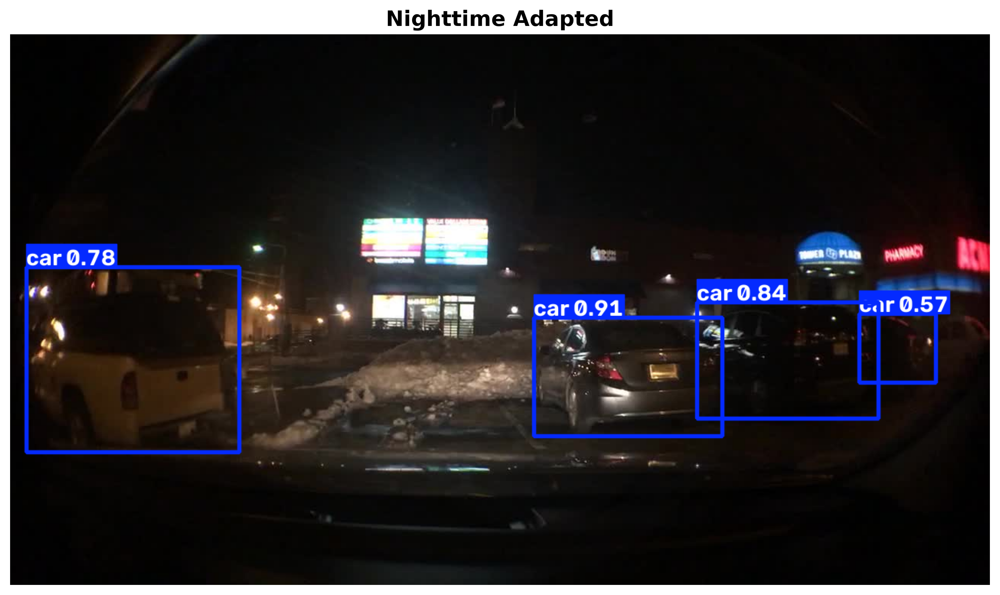


All three poster figures generated successfully.


In [15]:

# NightSight - Generate Three Poster Figures

from pathlib import Path
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO
from IPython.display import display, Image

# 1. Locate project
ROOT = next(
    (p for p in [Path.cwd(), Path.cwd().parent]
     if (p / "data/processed/nightsight_10k").exists()),
    None
)
assert ROOT is not None, "NightSight project not found."

DATA = ROOT / "data/processed/nightsight_10k"
IMAGE_DIR = DATA / "images/final_evaluation"

BASELINE_PATH = ROOT / "experiments/runs/yolo11s_daytime_10k/weights/best.pt"
ADAPTED_PATH = ROOT / "experiments/runs/yolo11s_night_adaptation_10k-2/weights/best.pt"

OUTPUT = ROOT / "results/poster_figures"
OUTPUT.mkdir(parents=True, exist_ok=True)

# 2. Select one nighttime image with multiple vehicles
IMAGE_PATH = next(IMAGE_DIR.glob("b29c5efd-754ba560.*"), None)

assert IMAGE_PATH is not None, "Selected image not found."
assert BASELINE_PATH.exists() and ADAPTED_PATH.exists()

# 3. Load image and models
original = cv2.imread(str(IMAGE_PATH))
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

baseline = YOLO(str(BASELINE_PATH))
adapted = YOLO(str(ADAPTED_PATH))

# 4. Generate predictions
baseline_result = baseline.predict(
    str(IMAGE_PATH), imgsz=640, conf=0.25, device=0, verbose=False
)[0]

adapted_result = adapted.predict(
    str(IMAGE_PATH), imgsz=640, conf=0.25, device=0, verbose=False
)[0]

baseline_image = cv2.cvtColor(
    baseline_result.plot(), cv2.COLOR_BGR2RGB
)

adapted_image = cv2.cvtColor(
    adapted_result.plot(), cv2.COLOR_BGR2RGB
)

# 5. Save three separate high-resolution figures
figures = [
    ("Figure_1_Nighttime_Input.png", original, "Nighttime Input Image"),
    ("Figure_2_Daytime_Baseline.png", baseline_image, "Daytime Baseline"),
    ("Figure_3_Nighttime_Adapted.png", adapted_image, "Nighttime Adapted")
]

for filename, image, title in figures:
    path = OUTPUT / filename

    plt.figure(figsize=(10, 6))
    plt.imshow(image)
    plt.title(title, fontsize=15, fontweight="bold")
    plt.axis("off")
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved:", path)
    display(Image(filename=str(path), width=650))

print("\nAll three poster figures generated successfully.")


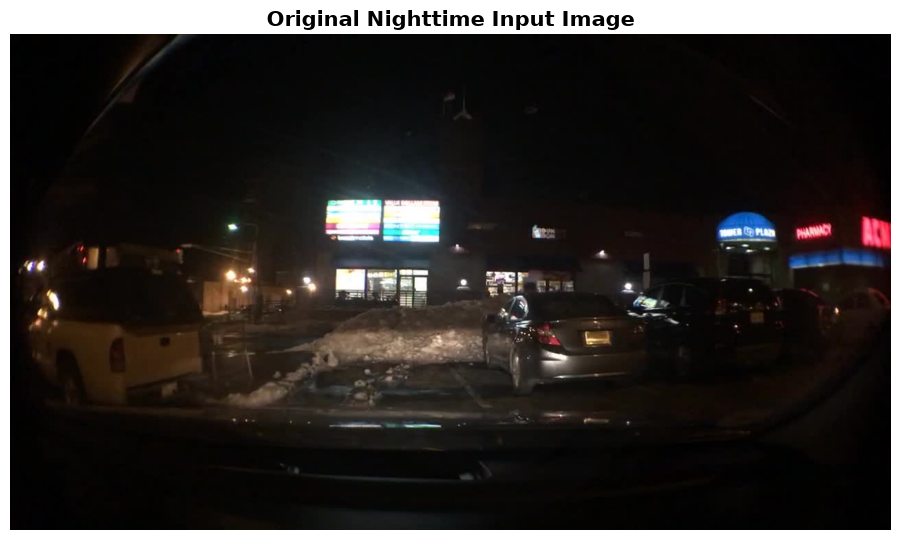

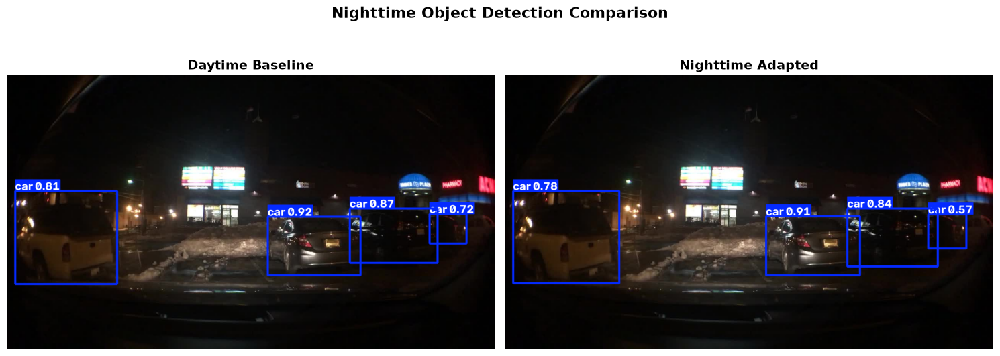

Two poster figures saved:
c:\CH\NightSight\results\poster_figures\Figure_1_Nighttime_Input.png
c:\CH\NightSight\results\poster_figures\Figure_2_Baseline_vs_Adapted.png


In [16]:

# NightSight - Generate 2 Poster Figures

from pathlib import Path
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Locate project
ROOT = next(
    (p for p in [Path.cwd(), Path.cwd().parent]
     if (p / "data/processed/nightsight_10k").exists()),
    None
)
assert ROOT is not None, "NightSight project not found."

DATA = ROOT / "data/processed/nightsight_10k"
IMAGE_DIR = DATA / "images/final_evaluation"

BASELINE_PATH = ROOT / "experiments/runs/yolo11s_daytime_10k/weights/best.pt"
ADAPTED_PATH = ROOT / "experiments/runs/yolo11s_night_adaptation_10k-2/weights/best.pt"

OUTPUT = ROOT / "results/poster_figures"
OUTPUT.mkdir(parents=True, exist_ok=True)

# Select the same nighttime image used in the earlier comparison
IMAGE_PATH = next(IMAGE_DIR.glob("b29c5efd-754ba560.*"), None)
assert IMAGE_PATH is not None, "Selected image not found."

# Load image and models
original = cv2.cvtColor(cv2.imread(str(IMAGE_PATH)), cv2.COLOR_BGR2RGB)

baseline = YOLO(str(BASELINE_PATH))
adapted = YOLO(str(ADAPTED_PATH))

# Generate predictions
baseline_result = baseline.predict(
    str(IMAGE_PATH), imgsz=640, conf=0.25, device=0, verbose=False
)[0]

adapted_result = adapted.predict(
    str(IMAGE_PATH), imgsz=640, conf=0.25, device=0, verbose=False
)[0]

baseline_image = cv2.cvtColor(baseline_result.plot(), cv2.COLOR_BGR2RGB)
adapted_image = cv2.cvtColor(adapted_result.plot(), cv2.COLOR_BGR2RGB)

# Figure 1: Original nighttime input
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.imshow(original)
ax.set_title("Original Nighttime Input Image", fontsize=15, fontweight="bold")
ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT / "Figure_1_Nighttime_Input.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# Figure 2: Baseline vs Adapted predictions
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].imshow(baseline_image)
axes[0].set_title("Daytime Baseline", fontsize=14, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(adapted_image)
axes[1].set_title("Nighttime Adapted", fontsize=14, fontweight="bold")
axes[1].axis("off")

fig.suptitle("Nighttime Object Detection Comparison",
             fontsize=16, fontweight="bold")
fig.tight_layout()
fig.savefig(OUTPUT / "Figure_2_Baseline_vs_Adapted.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Two poster figures saved:")
print(OUTPUT / "Figure_1_Nighttime_Input.png")
print(OUTPUT / "Figure_2_Baseline_vs_Adapted.png")
